<a href="https://colab.research.google.com/github/Gauravkumar000/CropNet-CNN-Disease-Detection/blob/main/Crop_Leaf_Disease_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

!nvidia-smi

import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))


Tue Nov 24 07:57:34 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   57C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:

# CELL 1: Check Google Colab Environment

import sys
import os
import platform

print("Python Version:", sys.version)
print("Platform:", platform.platform())

# Check GPU
!nvidia-smi

import tensorflow as tf

print("\nTensorFlow Version:", tf.__version__)
print("GPU Available:", tf.config.list_physical_devices('GPU'))


Python Version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
Tue Nov 24 08:00:39 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   55C    P8             14W /   70W |       3MiB /  15360MiB |      0%      Default |
|                         

In [4]:

# CELL 2: Install Project Dependencies

!pip install -q kagglehub pillow opencv-python-headless \
    scikit-learn pandas numpy matplotlib seaborn \
    streamlit

print("All required libraries installed successfully!")


All required libraries installed successfully!


In [5]:

# CELL 3: Import Libraries

import os
import random
import shutil
import pathlib
import time
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

from PIL import Image

import tensorflow as tf
from tensorflow.keras import layers, models

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")


All libraries imported successfully!


In [6]:

# CELL 4: Reproducibility

SEED = 42

os.environ["PYTHONHASHSEED"] = str(SEED)

random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed fixed:", SEED)


Random seed fixed: 42


In [7]:

# CELL 5: Project Configuration

PROJECT_NAME = "Automated Crop Leaf Disease Detection"

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

NUM_CLASSES = 15

EPOCHS = 35

LEARNING_RATE = 0.001

TEST_SIZE = 0.15
VALIDATION_SIZE = 0.15

DATASET_NAME = "PlantVillage"

PROJECT_DIR = "/content/Crop_Disease_Project"

os.makedirs(PROJECT_DIR, exist_ok=True)

MODEL_DIR = os.path.join(PROJECT_DIR, "models")
RESULT_DIR = os.path.join(PROJECT_DIR, "results")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "outputs")

os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULT_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Project configuration completed.")
print("Project directory:", PROJECT_DIR)


Project configuration completed.
Project directory: /content/Crop_Disease_Project


In [8]:

# CELL 6: Download PlantVillage Dataset

import kagglehub

dataset_path = kagglehub.dataset_download(
    "emmarex/plantdisease"
)

print("Dataset downloaded successfully!")
print("Dataset location:", dataset_path)


Using Colab cache for faster access to the 'plantdisease' dataset.
Dataset downloaded successfully!
Dataset location: /kaggle/input/plantdisease


In [9]:

# CELL 7: Inspect Dataset Structure

from pathlib import Path

dataset_path = Path(dataset_path)

print("Dataset Root:", dataset_path)

for root, dirs, files in os.walk(dataset_path):
    level = str(root).replace(str(dataset_path), "").count(os.sep)

    if level <= 3:
        indent = " " * 4 * level

        print(
            indent,
            os.path.basename(root),
            "| Files:", len(files)
        )


Dataset Root: /kaggle/input/plantdisease
 plantdisease | Files: 0
     PlantVillage | Files: 0
         Pepper__bell___Bacterial_spot | Files: 997
         Potato___healthy | Files: 152
         Tomato_Leaf_Mold | Files: 952
         Tomato__Tomato_YellowLeaf__Curl_Virus | Files: 3209
         Tomato_Bacterial_spot | Files: 2127
         Tomato_Septoria_leaf_spot | Files: 1771
         Tomato_healthy | Files: 1591
         Tomato_Spider_mites_Two_spotted_spider_mite | Files: 1676
         Tomato_Early_blight | Files: 1000
         Tomato__Target_Spot | Files: 1404
         Pepper__bell___healthy | Files: 1478
         Potato___Late_blight | Files: 1000
         Tomato_Late_blight | Files: 1909
         Potato___Early_blight | Files: 1000
         Tomato__Tomato_mosaic_virus | Files: 373
     plantvillage | Files: 0
         PlantVillage | Files: 0
             Pepper__bell___Bacterial_spot | Files: 997
             Potato___healthy | Files: 152
             Tomato_Leaf_Mold | Files: 95

In [10]:

# CELL 8: Locate Image Class Directory

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

candidate_dirs = []

for current_root, dirs, files in os.walk(dataset_path):

    image_files = [
        f for f in files
        if Path(f).suffix.lower() in IMAGE_EXTENSIONS
    ]

    if image_files:
        candidate_dirs.append(
            (Path(current_root), len(image_files))
        )

# Display directories containing images
for folder, count in sorted(
    candidate_dirs,
    key=lambda x: x[1],
    reverse=True
)[:20]:

    print(folder, "->", count, "images")


/kaggle/input/plantdisease/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus -> 3208 images
/kaggle/input/plantdisease/plantvillage/PlantVillage/Tomato__Tomato_YellowLeaf__Curl_Virus -> 3208 images
/kaggle/input/plantdisease/PlantVillage/Tomato_Bacterial_spot -> 2127 images
/kaggle/input/plantdisease/plantvillage/PlantVillage/Tomato_Bacterial_spot -> 2127 images
/kaggle/input/plantdisease/PlantVillage/Tomato_Late_blight -> 1909 images
/kaggle/input/plantdisease/plantvillage/PlantVillage/Tomato_Late_blight -> 1909 images
/kaggle/input/plantdisease/PlantVillage/Tomato_Septoria_leaf_spot -> 1771 images
/kaggle/input/plantdisease/plantvillage/PlantVillage/Tomato_Septoria_leaf_spot -> 1771 images
/kaggle/input/plantdisease/PlantVillage/Tomato_Spider_mites_Two_spotted_spider_mite -> 1676 images
/kaggle/input/plantdisease/plantvillage/PlantVillage/Tomato_Spider_mites_Two_spotted_spider_mite -> 1676 images
/kaggle/input/plantdisease/PlantVillage/Tomato_healthy -> 1591 images
/kaggle/input/pla

In [12]:

# CORRECTED CELL 1.9 + 1.10
# Automatically detect PlantVillage class folders

from pathlib import Path
from collections import defaultdict

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

def count_images(folder):
    return sum(
        1 for p in Path(folder).rglob("*")
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    )

# Confirm dataset location
dataset_path = Path(dataset_path)

print("Dataset location:", dataset_path)
print("Dataset exists:", dataset_path.exists())

if not dataset_path.exists():
    raise FileNotFoundError("Dataset path does not exist!")

# Required crop prefixes
crop_prefixes = ("pepper", "potato", "tomato")

# Find class folders and group them by parent directory
class_groups = defaultdict(list)

for current_root, dirs, files in os.walk(dataset_path):

    folder = Path(current_root)

    if folder.name.lower().startswith(crop_prefixes):

        image_count = count_images(folder)

        if image_count > 0:
            class_groups[folder.parent].append(
                (folder, image_count)
            )

# Display detected groups
print("\nDetected class-folder groups:")

for parent, classes in class_groups.items():
    print("\nParent:", parent)
    print("Classes found:", len(classes))

    for folder, count in classes:
        print(" ", folder.name, ":", count, "images")

# Select the parent containing all 15 required classes
valid_groups = [
    (parent, classes)
    for parent, classes in class_groups.items()
    if len(classes) == 15
]

if not valid_groups:
    raise RuntimeError(
        "Could not find exactly 15 crop disease classes. "
        "Check the detected folder output above."
    )

# Select group with maximum total images
DATASET_ROOT, selected_group = max(
    valid_groups,
    key=lambda item: sum(x[1] for x in item[1])
)

selected_classes = sorted(
    folder.name for folder, count in selected_group
)

class_counts = {
    folder.name: count
    for folder, count in selected_group
}

print("\n===================================")
print("DATASET ROOT:", DATASET_ROOT)
print("TOTAL CLASSES:", len(selected_classes))
print("TOTAL IMAGES:", sum(class_counts.values()))
print("===================================")

for i, name in enumerate(selected_classes, 1):
    print(i, name, ":", class_counts[name])

assert len(selected_classes) == 15

print("\nSUCCESS: All 15 classes detected!")


Dataset location: /kaggle/input/plantdisease
Dataset exists: True

Detected class-folder groups:

Parent: /kaggle/input/plantdisease/PlantVillage
Classes found: 15
  Pepper__bell___Bacterial_spot : 997 images
  Potato___healthy : 152 images
  Tomato_Leaf_Mold : 952 images
  Tomato__Tomato_YellowLeaf__Curl_Virus : 3208 images
  Tomato_Bacterial_spot : 2127 images
  Tomato_Septoria_leaf_spot : 1771 images
  Tomato_healthy : 1591 images
  Tomato_Spider_mites_Two_spotted_spider_mite : 1676 images
  Tomato_Early_blight : 1000 images
  Tomato__Target_Spot : 1404 images
  Pepper__bell___healthy : 1478 images
  Potato___Late_blight : 1000 images
  Tomato_Late_blight : 1909 images
  Potato___Early_blight : 1000 images
  Tomato__Tomato_mosaic_virus : 373 images

Parent: /kaggle/input/plantdisease/plantvillage/PlantVillage
Classes found: 15
  Pepper__bell___Bacterial_spot : 997 images
  Potato___healthy : 152 images
  Tomato_Leaf_Mold : 952 images
  Tomato__Tomato_YellowLeaf__Curl_Virus : 3208 im

In [13]:

# CELL 11: Dataset Image Count

class_counts = {}

for class_name in selected_classes:

    class_folder = DATASET_ROOT / class_name

    image_count = sum(
        1 for p in class_folder.iterdir()
        if p.is_file()
        and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    class_counts[class_name] = image_count

dataset_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Class", "Image Count"]
)

display(dataset_df)

print("\nTotal Images:", dataset_df["Image Count"].sum())
print("Total Classes:", len(dataset_df))


,Class,Image Count
0,Pepper__bell___Bacterial_spot,997
1,Pepper__bell___healthy,1478
2,Potato___Early_blight,1000
3,Potato___Late_blight,1000
4,Potato___healthy,152
5,Tomato_Bacterial_spot,2127
6,Tomato_Early_blight,1000
7,Tomato_Late_blight,1909
8,Tomato_Leaf_Mold,952
9,Tomato_Septoria_leaf_spot,1771



Total Images: 20638
Total Classes: 15


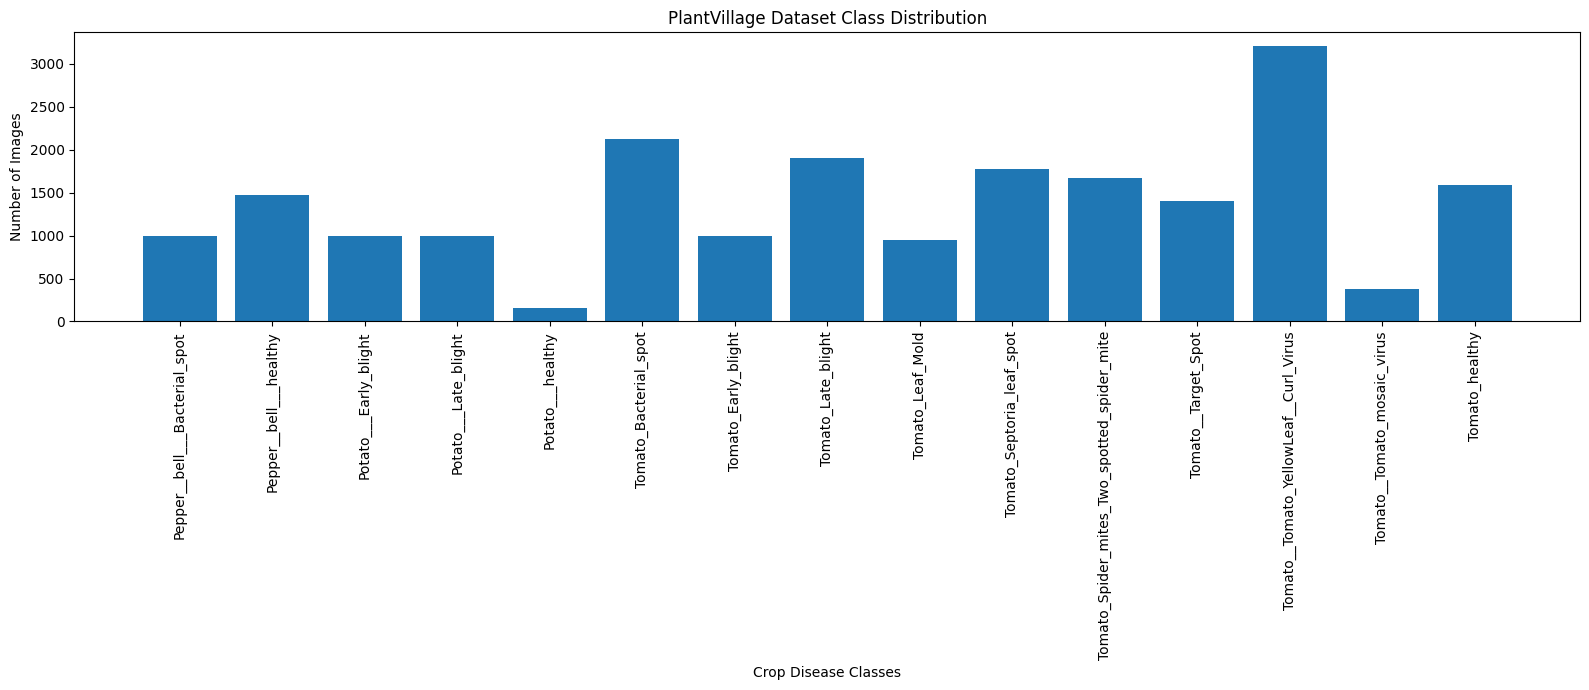

In [14]:

# CELL 12: Class Distribution Graph

plt.figure(figsize=(16, 7))

plt.bar(
    dataset_df["Class"],
    dataset_df["Image Count"]
)

plt.xticks(rotation=90)

plt.xlabel("Crop Disease Classes")
plt.ylabel("Number of Images")

plt.title("PlantVillage Dataset Class Distribution")

plt.tight_layout()

plt.savefig(
    os.path.join(RESULT_DIR, "class_distribution.png"),
    dpi=300
)

plt.show()


In [15]:

# CELL 13: Dataset Verification

actual_total = dataset_df["Image Count"].sum()

print("REPORT DATASET IMAGES: 20,638")
print("ACTUAL DATASET IMAGES:", actual_total)

print("\nREPORT CLASSES: 15")
print("ACTUAL CLASSES:", len(selected_classes))

if actual_total == 20638 and len(selected_classes) == 15:
    print("\nDataset matches reported specifications.")
else:
    print("\nWARNING: Dataset differs from report.")
    print("Use actual dataset counts in final results.")


REPORT DATASET IMAGES: 20,638
ACTUAL DATASET IMAGES: 20638

REPORT CLASSES: 15
ACTUAL CLASSES: 15

Dataset matches reported specifications.


In [16]:

# PART 2 - CELL 1
# Verify all 15 PlantVillage classes

from pathlib import Path
import os
import pandas as pd
import numpy as np

IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".webp"}

assert Path(DATASET_ROOT).exists(), "Dataset root not found!"

selected_classes = sorted(selected_classes)

print("DATASET ROOT:", DATASET_ROOT)
print("TOTAL CLASSES:", len(selected_classes))

assert len(selected_classes) == 15, (
    f"Expected 15 classes, found {len(selected_classes)}"
)

for i, class_name in enumerate(selected_classes, 1):

    class_path = Path(DATASET_ROOT) / class_name

    assert class_path.exists(), f"Missing folder: {class_name}"

    count = sum(
        1 for p in class_path.rglob("*")
        if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS
    )

    print(f"{i:02d}. {class_name}: {count} images")

    assert count > 0, f"No images in {class_name}"

print("\nSUCCESS: All 15 classes verified!")


DATASET ROOT: /kaggle/input/plantdisease/PlantVillage
TOTAL CLASSES: 15
01. Pepper__bell___Bacterial_spot: 997 images
02. Pepper__bell___healthy: 1478 images
03. Potato___Early_blight: 1000 images
04. Potato___Late_blight: 1000 images
05. Potato___healthy: 152 images
06. Tomato_Bacterial_spot: 2127 images
07. Tomato_Early_blight: 1000 images
08. Tomato_Late_blight: 1909 images
09. Tomato_Leaf_Mold: 952 images
10. Tomato_Septoria_leaf_spot: 1771 images
11. Tomato_Spider_mites_Two_spotted_spider_mite: 1676 images
12. Tomato__Target_Spot: 1404 images
13. Tomato__Tomato_YellowLeaf__Curl_Virus: 3208 images
14. Tomato__Tomato_mosaic_virus: 373 images
15. Tomato_healthy: 1591 images

SUCCESS: All 15 classes verified!


In [17]:

# PART 2 - CELL 2
# Collect image paths and labels

image_records = []

for class_index, class_name in enumerate(selected_classes):

    class_folder = Path(DATASET_ROOT) / class_name

    for image_path in sorted(class_folder.rglob("*")):

        if (
            image_path.is_file()
            and image_path.suffix.lower() in IMAGE_EXTENSIONS
        ):

            image_records.append({
                "image_path": str(image_path),
                "class_name": class_name,
                "label": class_index
            })

image_df = pd.DataFrame(image_records)

print("Total image records:", len(image_df))
print("Total classes:", image_df["class_name"].nunique())

display(image_df.head(10))

print("\nClass labels:")
for i, name in enumerate(selected_classes):
    print(i, ":", name)

assert image_df["class_name"].nunique() == 15

print("\nImage paths and labels collected successfully!")


Total image records: 20638
Total classes: 15


,image_path,class_name,label
0,/kaggle/input/plantdisease/PlantVillage/Pepper...,Pepper__bell___Bacterial_spot,0
1,/kaggle/input/plantdisease/PlantVillage/Pepper...,Pepper__bell___Bacterial_spot,0
2,/kaggle/input/plantdisease/PlantVillage/Pepper...,Pepper__bell___Bacterial_spot,0
3,/kaggle/input/plantdisease/PlantVillage/Pepper...,Pepper__bell___Bacterial_spot,0
4,/kaggle/input/plantdisease/PlantVillage/Pepper...,Pepper__bell___Bacterial_spot,0
5,/kaggle/input/plantdisease/PlantVillage/Pepper...,Pepper__bell___Bacterial_spot,0
6,/kaggle/input/plantdisease/PlantVillage/Pepper...,Pepper__bell___Bacterial_spot,0
7,/kaggle/input/plantdisease/PlantVillage/Pepper...,Pepper__bell___Bacterial_spot,0
8,/kaggle/input/plantdisease/PlantVillage/Pepper...,Pepper__bell___Bacterial_spot,0
9,/kaggle/input/plantdisease/PlantVillage/Pepper...,Pepper__bell___Bacterial_spot,0



Class labels:
0 : Pepper__bell___Bacterial_spot
1 : Pepper__bell___healthy
2 : Potato___Early_blight
3 : Potato___Late_blight
4 : Potato___healthy
5 : Tomato_Bacterial_spot
6 : Tomato_Early_blight
7 : Tomato_Late_blight
8 : Tomato_Leaf_Mold
9 : Tomato_Septoria_leaf_spot
10 : Tomato_Spider_mites_Two_spotted_spider_mite
11 : Tomato__Target_Spot
12 : Tomato__Tomato_YellowLeaf__Curl_Virus
13 : Tomato__Tomato_mosaic_virus
14 : Tomato_healthy

Image paths and labels collected successfully!


In [18]:

# PART 2 - CELL 3
# Detect corrupted images

from PIL import Image

valid_records = []
corrupted_records = []

for index, row in image_df.iterrows():

    image_path = row["image_path"]

    try:
        with Image.open(image_path) as img:
            img.verify()

        # Reopen and check actual image dimensions
        with Image.open(image_path) as img:
            width, height = img.size

            if width <= 0 or height <= 0:
                raise ValueError("Invalid image dimensions")

        valid_records.append(row.to_dict())

    except Exception as e:

        corrupted_records.append({
            "image_path": image_path,
            "error": str(e)
        })

valid_df = pd.DataFrame(valid_records)

corrupted_df = pd.DataFrame(
    corrupted_records,
    columns=["image_path", "error"]
)

print("Original Images:", len(image_df))
print("Valid Images:", len(valid_df))
print("Corrupted Images:", len(corrupted_df))

print(
    "Corruption Percentage:",
    round(
        len(corrupted_df) / max(len(image_df), 1) * 100,
        2
    ),
    "%"
)

if len(corrupted_df) > 0:
    display(corrupted_df.head(10))
else:
    print("No corrupted images found!")

assert len(valid_df) > 0

print("\nCorrupted image checking completed!")


Original Images: 20638
Valid Images: 20638
Corrupted Images: 0
Corruption Percentage: 0.0 %
No corrupted images found!

Corrupted image checking completed!


In [19]:

# PART 2 - CELL 4
# Save image validation report

corrupted_df.to_csv(
    os.path.join(RESULT_DIR, "corrupted_images.csv"),
    index=False
)

valid_df.to_csv(
    os.path.join(RESULT_DIR, "valid_images.csv"),
    index=False
)

print("Validation reports saved successfully!")


Validation reports saved successfully!


In [20]:

# PART 2 - CELL 5
# RGB Conversion and Resizing

from PIL import Image

PREPROCESSED_DIR = os.path.join(
    PROJECT_DIR,
    "preprocessed_images"
)

os.makedirs(PREPROCESSED_DIR, exist_ok=True)

IMAGE_SIZE = (224, 224)

processed_records = []

for class_index, class_name in enumerate(selected_classes):

    source_folder = Path(DATASET_ROOT) / class_name

    output_folder = Path(PREPROCESSED_DIR) / class_name
    output_folder.mkdir(parents=True, exist_ok=True)

    class_images = valid_df[
        valid_df["class_name"] == class_name
    ]

    print("\nProcessing:", class_name)

    for image_number, (_, row) in enumerate(
        class_images.iterrows()
    ):

        source_path = row["image_path"]

        try:
            with Image.open(source_path) as img:

                # Convert image to RGB
                img = img.convert("RGB")

                # Resize using Bilinear interpolation
                img = img.resize(
                    IMAGE_SIZE,
                    Image.Resampling.BILINEAR
                )

                # Save preprocessed image
                output_name = f"{class_index}_{image_number:06d}.jpg"

                output_path = output_folder / output_name

                img.save(
                    output_path,
                    format="JPEG",
                    quality=95
                )

                processed_records.append({
                    "image_path": str(output_path),
                    "class_name": class_name,
                    "label": class_index
                })

        except Exception as e:
            print("Processing failed:", source_path, str(e))

print("\nRGB conversion and resizing completed!")

print("Processed Images:", len(processed_records))



Processing: Pepper__bell___Bacterial_spot

Processing: Pepper__bell___healthy

Processing: Potato___Early_blight

Processing: Potato___Late_blight

Processing: Potato___healthy

Processing: Tomato_Bacterial_spot

Processing: Tomato_Early_blight

Processing: Tomato_Late_blight

Processing: Tomato_Leaf_Mold

Processing: Tomato_Septoria_leaf_spot

Processing: Tomato_Spider_mites_Two_spotted_spider_mite

Processing: Tomato__Target_Spot

Processing: Tomato__Tomato_YellowLeaf__Curl_Virus

Processing: Tomato__Tomato_mosaic_virus

Processing: Tomato_healthy

RGB conversion and resizing completed!
Processed Images: 20638


In [21]:

# PART 2 - CELL 6
# Create final processed image dataframe

processed_df = pd.DataFrame(processed_records)

print("Processed Dataset Shape:", processed_df.shape)

display(processed_df.head(10))

print("\nClass-wise processed images:")

display(
    processed_df.groupby("class_name")
    .size()
    .reset_index(name="Image Count")
)

assert len(processed_df) > 0
assert processed_df["class_name"].nunique() == 15

print("\nProcessed dataset verified successfully!")


Processed Dataset Shape: (20638, 3)


,image_path,class_name,label
0,/content/Crop_Disease_Project/preprocessed_ima...,Pepper__bell___Bacterial_spot,0
1,/content/Crop_Disease_Project/preprocessed_ima...,Pepper__bell___Bacterial_spot,0
2,/content/Crop_Disease_Project/preprocessed_ima...,Pepper__bell___Bacterial_spot,0
3,/content/Crop_Disease_Project/preprocessed_ima...,Pepper__bell___Bacterial_spot,0
4,/content/Crop_Disease_Project/preprocessed_ima...,Pepper__bell___Bacterial_spot,0
5,/content/Crop_Disease_Project/preprocessed_ima...,Pepper__bell___Bacterial_spot,0
6,/content/Crop_Disease_Project/preprocessed_ima...,Pepper__bell___Bacterial_spot,0
7,/content/Crop_Disease_Project/preprocessed_ima...,Pepper__bell___Bacterial_spot,0
8,/content/Crop_Disease_Project/preprocessed_ima...,Pepper__bell___Bacterial_spot,0
9,/content/Crop_Disease_Project/preprocessed_ima...,Pepper__bell___Bacterial_spot,0



Class-wise processed images:


,class_name,Image Count
0,Pepper__bell___Bacterial_spot,997
1,Pepper__bell___healthy,1478
2,Potato___Early_blight,1000
3,Potato___Late_blight,1000
4,Potato___healthy,152
5,Tomato_Bacterial_spot,2127
6,Tomato_Early_blight,1000
7,Tomato_Late_blight,1909
8,Tomato_Leaf_Mold,952
9,Tomato_Septoria_leaf_spot,1771



Processed dataset verified successfully!


In [22]:

# PART 2 - CELL 7
# Verify dimensions and RGB format

dimension_errors = []
mode_errors = []

for path in processed_df["image_path"]:

    with Image.open(path) as img:

        if img.size != (224, 224):
            dimension_errors.append(path)

        if img.mode != "RGB":
            mode_errors.append(path)

print("Incorrect dimensions:", len(dimension_errors))
print("Incorrect color modes:", len(mode_errors))

assert len(dimension_errors) == 0
assert len(mode_errors) == 0

print("\nAll images are 224x224 RGB!")


Incorrect dimensions: 0
Incorrect color modes: 0

All images are 224x224 RGB!


In [23]:

# PART 2 - CELL 8
# Test Pixel Normalization

sample_path = processed_df.iloc[0]["image_path"]

sample_image = np.array(
    Image.open(sample_path).convert("RGB")
)

normalized_image = sample_image.astype(
    np.float32
) / 255.0

print("Original Image Shape:", sample_image.shape)
print("Original Pixel Minimum:", sample_image.min())
print("Original Pixel Maximum:", sample_image.max())

print("\nNormalized Image Shape:", normalized_image.shape)
print("Normalized Pixel Minimum:", normalized_image.min())
print("Normalized Pixel Maximum:", normalized_image.max())

assert normalized_image.shape == (224, 224, 3)
assert normalized_image.min() >= 0.0
assert normalized_image.max() <= 1.0

print("\nNormalization verified successfully!")


Original Image Shape: (224, 224, 3)
Original Pixel Minimum: 0
Original Pixel Maximum: 239

Normalized Image Shape: (224, 224, 3)
Normalized Pixel Minimum: 0.0
Normalized Pixel Maximum: 0.9372549

Normalization verified successfully!


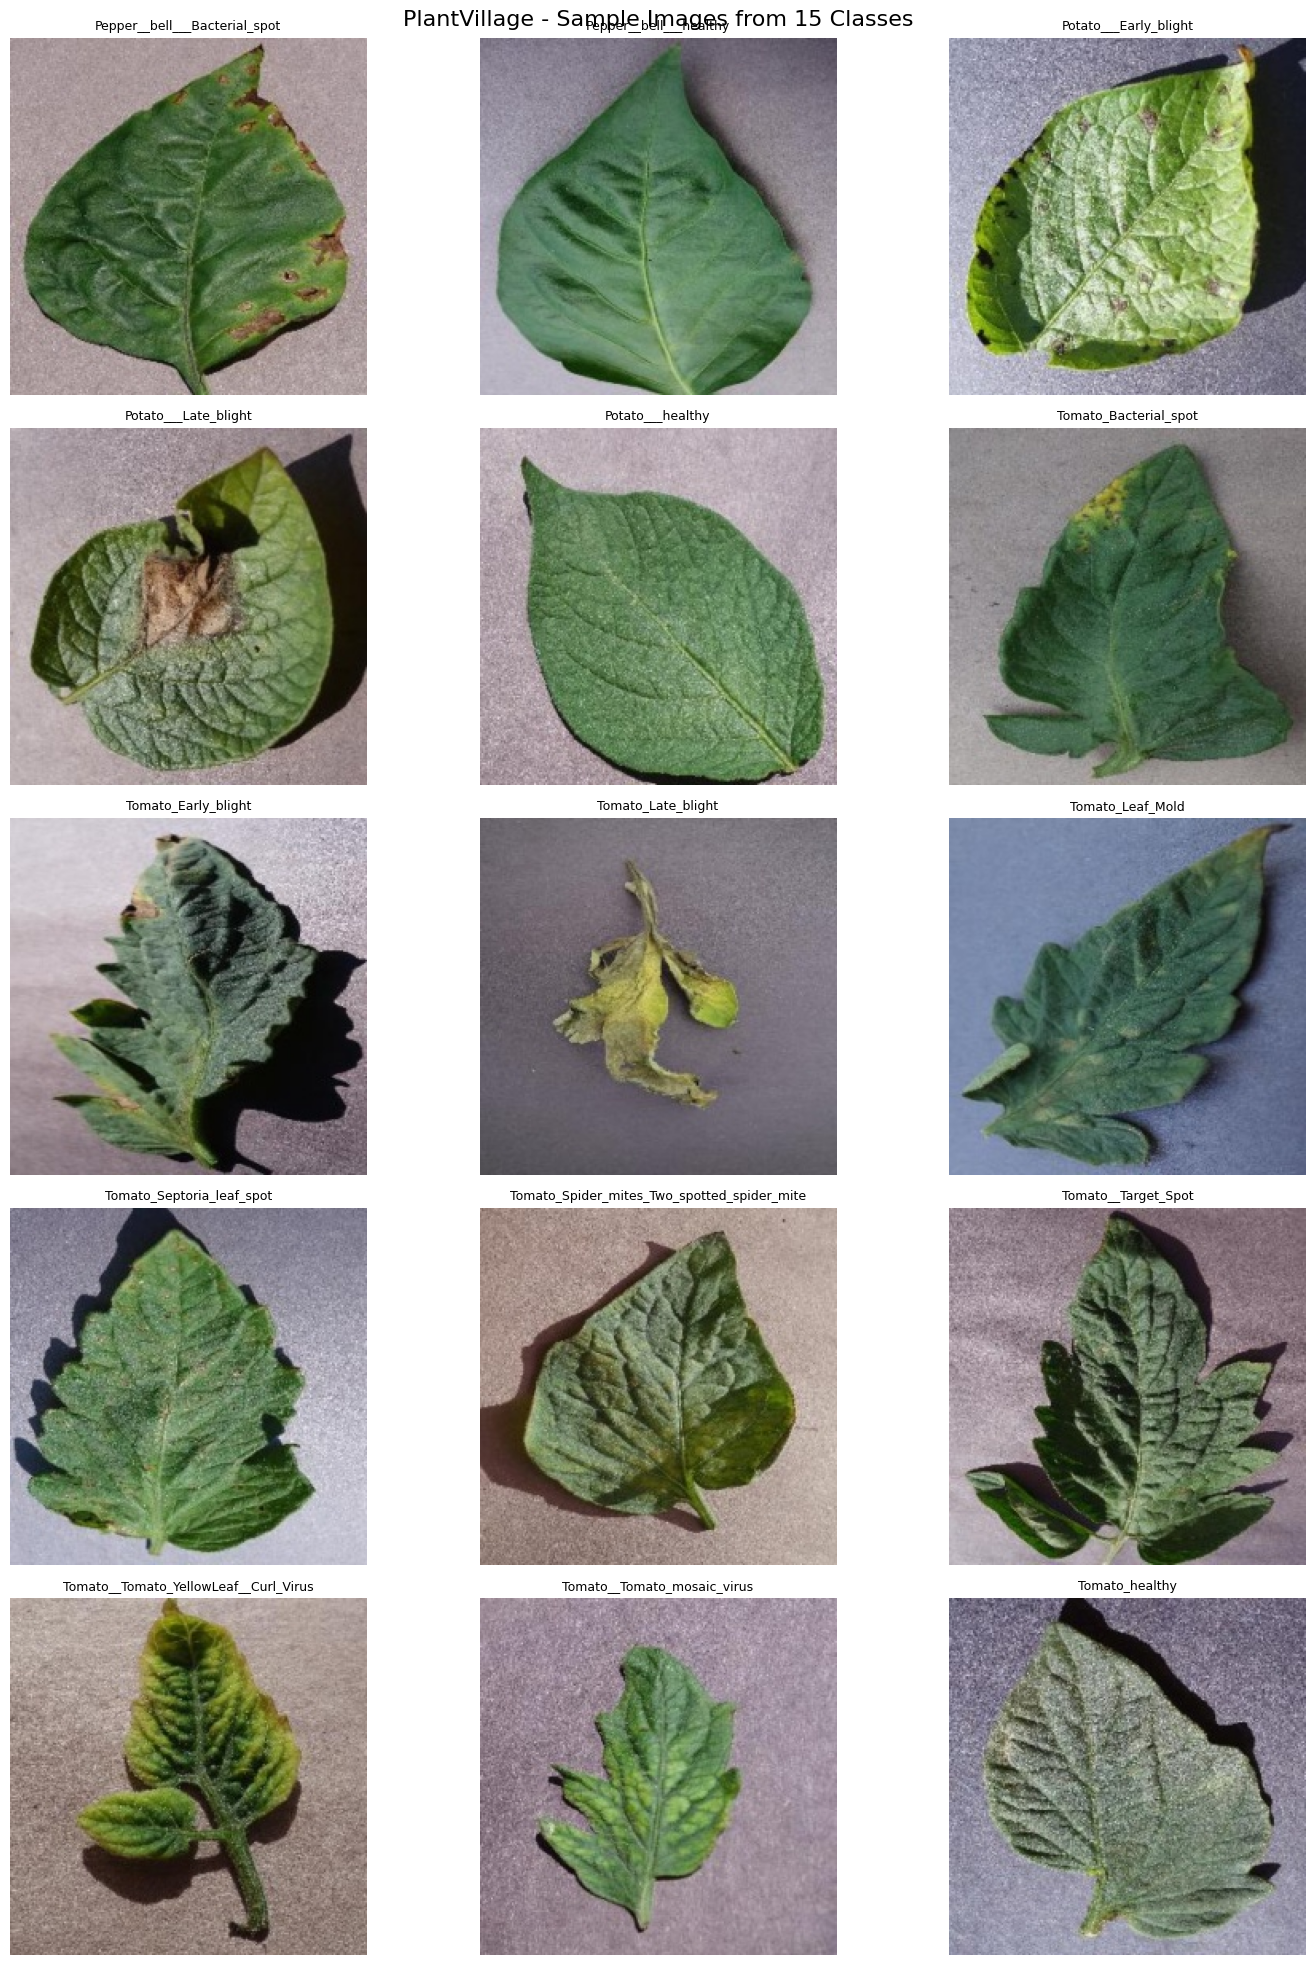

In [24]:

# PART 2 - CELL 9
# Visualize sample images from 15 classes

fig, axes = plt.subplots(
    5, 3,
    figsize=(15, 20)
)

for i, class_name in enumerate(selected_classes):

    class_data = processed_df[
        processed_df["class_name"] == class_name
    ]

    sample_row = class_data.sample(
        n=1,
        random_state=SEED
    ).iloc[0]

    img = Image.open(
        sample_row["image_path"]
    ).convert("RGB")

    row = i // 3
    col = i % 3

    axes[row, col].imshow(img)
    axes[row, col].set_title(
        class_name,
        fontsize=9
    )
    axes[row, col].axis("off")

plt.suptitle(
    "PlantVillage - Sample Images from 15 Classes",
    fontsize=16
)

plt.tight_layout()

plt.savefig(
    os.path.join(RESULT_DIR, "sample_images_15_classes.png"),
    dpi=300
)

plt.show()


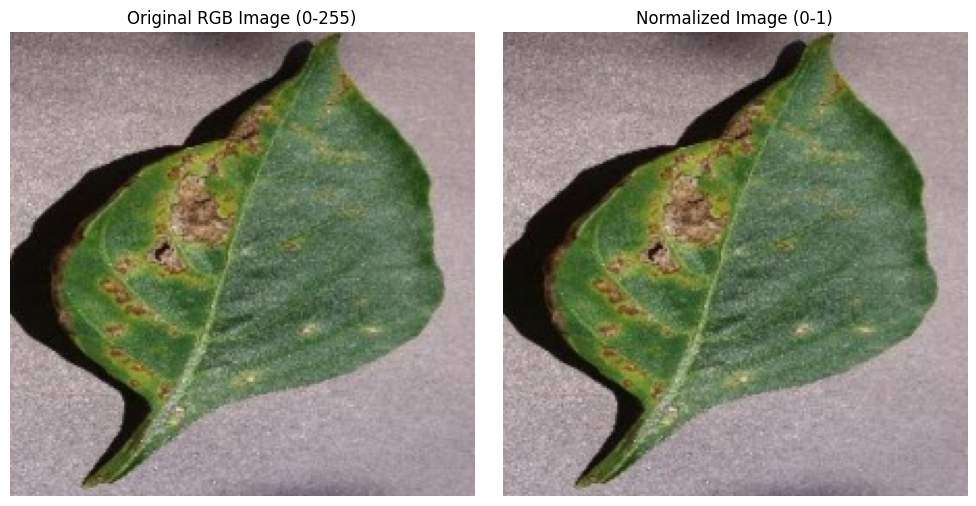

In [25]:

# PART 2 - CELL 10
# Original vs normalized image visualization

fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(sample_image)
axes[0].set_title("Original RGB Image (0-255)")
axes[0].axis("off")

axes[1].imshow(normalized_image)
axes[1].set_title("Normalized Image (0-1)")
axes[1].axis("off")

plt.tight_layout()

plt.savefig(
    os.path.join(RESULT_DIR, "normalization_comparison.png"),
    dpi=300
)

plt.show()


In [26]:

# PART 2 - CELL 11
# Dataset Statistical Analysis

class_statistics = (
    processed_df
    .groupby("class_name")
    .agg(
        Image_Count=("image_path", "count")
    )
    .reset_index()
)

total_images = len(processed_df)

print("========== DATASET STATISTICS ==========")

print("Total Classes:", len(selected_classes))
print("Total Processed Images:", total_images)

print(
    "Average Images per Class:",
    round(total_images / len(selected_classes), 2)
)

print(
    "Minimum Class Images:",
    class_statistics["Image_Count"].min()
)

print(
    "Maximum Class Images:",
    class_statistics["Image_Count"].max()
)

print("\nClass-wise Statistics:")

display(class_statistics)

class_statistics.to_csv(
    os.path.join(RESULT_DIR, "dataset_statistics.csv"),
    index=False
)


========== DATASET STATISTICS ==========
Total Classes: 15
Total Processed Images: 20638
Average Images per Class: 1375.87
Minimum Class Images: 152
Maximum Class Images: 3208

Class-wise Statistics:


,class_name,Image_Count
0,Pepper__bell___Bacterial_spot,997
1,Pepper__bell___healthy,1478
2,Potato___Early_blight,1000
3,Potato___Late_blight,1000
4,Potato___healthy,152
5,Tomato_Bacterial_spot,2127
6,Tomato_Early_blight,1000
7,Tomato_Late_blight,1909
8,Tomato_Leaf_Mold,952
9,Tomato_Septoria_leaf_spot,1771


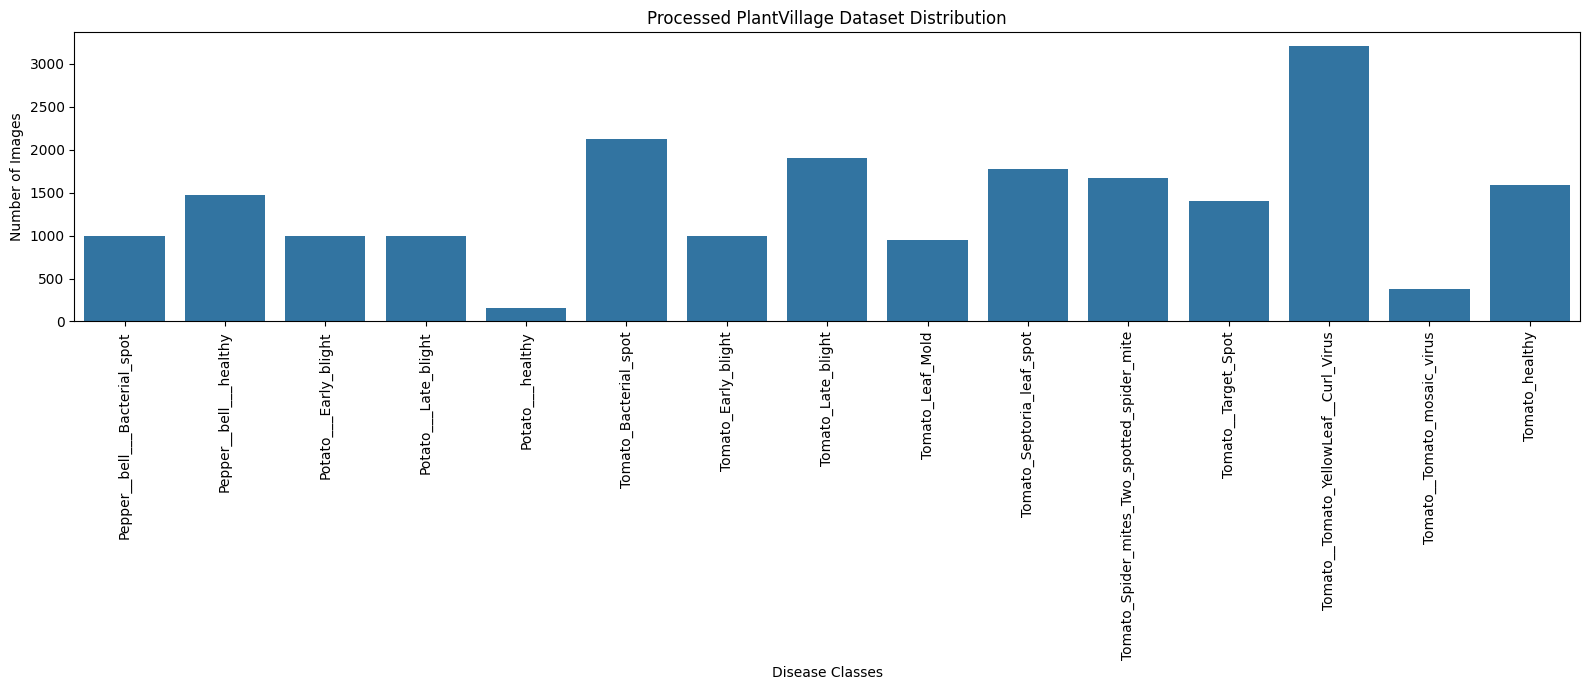

In [27]:

# PART 2 - CELL 12
# Final dataset distribution graph

plt.figure(figsize=(16, 7))

sns.barplot(
    data=class_statistics,
    x="class_name",
    y="Image_Count"
)

plt.xticks(rotation=90)

plt.xlabel("Disease Classes")
plt.ylabel("Number of Images")

plt.title("Processed PlantVillage Dataset Distribution")

plt.tight_layout()

plt.savefig(
    os.path.join(RESULT_DIR, "processed_class_distribution.png"),
    dpi=300
)

plt.show()


In [28]:

# PART 2 - CELL 13
# Stratified Train Validation Test Split

from sklearn.model_selection import train_test_split

SEED = 42

X = processed_df["image_path"].values
y = processed_df["label"].values

TOTAL_IMAGES = len(processed_df)

# Use exact report counts when all 20,638 images are available.
if TOTAL_IMAGES == 20638:

    X_train, X_temp, y_train, y_temp = train_test_split(
        X,
        y,
        train_size=14447,
        random_state=SEED,
        stratify=y
    )

    X_val, X_test, y_val, y_test = train_test_split(
        X_temp,
        y_temp,
        train_size=3095,
        test_size=3096,
        random_state=SEED,
        stratify=y_temp
    )

else:

    print(
        "WARNING: Actual processed image count differs "
        "from SRS report."
    )

    print("Using approximate 70:15:15 stratified split.")

    X_train, X_temp, y_train, y_temp = train_test_split(
        X,
        y,
        test_size=0.30,
        random_state=SEED,
        stratify=y
    )

    X_val, X_test, y_val, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=0.50,
        random_state=SEED,
        stratify=y_temp
    )

print("Training Images:", len(X_train))
print("Validation Images:", len(X_val))
print("Testing Images:", len(X_test))

print(
    "Total:",
    len(X_train) + len(X_val) + len(X_test)
)

assert len(X_train) + len(X_val) + len(X_test) == TOTAL_IMAGES

print("\nStratified split completed!")


Training Images: 14447
Validation Images: 3095
Testing Images: 3096
Total: 20638

Stratified split completed!


In [29]:

# PART 2 - CELL 14
# Class distribution in Train, Validation and Test

def get_distribution(labels, split_name):

    counts = pd.Series(labels).value_counts().sort_index()

    return pd.DataFrame({
        "Class": selected_classes,
        split_name: [
            int(counts.get(i, 0))
            for i in range(len(selected_classes))
        ]
    })

train_stats = get_distribution(y_train, "Training")
val_stats = get_distribution(y_val, "Validation")
test_stats = get_distribution(y_test, "Testing")

split_statistics = (
    train_stats
    .merge(val_stats, on="Class")
    .merge(test_stats, on="Class")
)

display(split_statistics)

assert (split_statistics["Training"] > 0).all()
assert (split_statistics["Validation"] > 0).all()
assert (split_statistics["Testing"] > 0).all()

print("\nAll 15 classes exist in all three splits!")


,Class,Training,Validation,Testing
0,Pepper__bell___Bacterial_spot,698,150,149
1,Pepper__bell___healthy,1035,222,221
2,Potato___Early_blight,700,150,150
3,Potato___Late_blight,700,150,150
4,Potato___healthy,106,23,23
5,Tomato_Bacterial_spot,1489,319,319
6,Tomato_Early_blight,700,150,150
7,Tomato_Late_blight,1336,286,287
8,Tomato_Leaf_Mold,666,143,143
9,Tomato_Septoria_leaf_spot,1240,265,266



All 15 classes exist in all three splits!


In [30]:

# PART 2 - CELL 15
# Save dataset splits

train_df = pd.DataFrame({
    "image_path": X_train,
    "label": y_train
})

val_df = pd.DataFrame({
    "image_path": X_val,
    "label": y_val
})

test_df = pd.DataFrame({
    "image_path": X_test,
    "label": y_test
})

train_df.to_csv(
    os.path.join(RESULT_DIR, "train_dataset.csv"),
    index=False
)

val_df.to_csv(
    os.path.join(RESULT_DIR, "validation_dataset.csv"),
    index=False
)

test_df.to_csv(
    os.path.join(RESULT_DIR, "test_dataset.csv"),
    index=False
)

split_statistics.to_csv(
    os.path.join(RESULT_DIR, "split_statistics.csv"),
    index=False
)

print("All dataset split CSV files saved!")

print("Training:", len(train_df))
print("Validation:", len(val_df))
print("Testing:", len(test_df))


All dataset split CSV files saved!
Training: 14447
Validation: 3095
Testing: 3096


In [31]:

# PART 2 - CELL 16
# TensorFlow Dataset Pipeline

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

NUM_CLASSES = len(selected_classes)

def preprocess_image(image_path, label):

    image = tf.io.read_file(image_path)

    image = tf.io.decode_image(
        image,
        channels=3,
        expand_animations=False
    )

    image.set_shape([None, None, 3])

    image = tf.image.resize(
        image,
        IMAGE_SIZE,
        method="bilinear"
    )

    image = tf.cast(
        image,
        tf.float32
    ) / 255.0

    label = tf.one_hot(
        tf.cast(label, tf.int32),
        depth=NUM_CLASSES
    )

    return image, label


def create_dataset(paths, labels, training=False):

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    dataset = dataset.map(
        preprocess_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)

    dataset = dataset.prefetch(
        tf.data.AUTOTUNE
    )

    return dataset


train_ds = create_dataset(
    X_train, y_train, training=True
)

val_ds = create_dataset(
    X_val, y_val, training=False
)

test_ds = create_dataset(
    X_test, y_test, training=False
)

print("TensorFlow datasets created successfully!")


TensorFlow datasets created successfully!


In [32]:

# PART 2 - CELL 17
# Verify TensorFlow Input Pipeline

for images, labels in train_ds.take(1):

    print("Image Batch Shape:", images.shape)
    print("Label Batch Shape:", labels.shape)

    print("Pixel Minimum:", tf.reduce_min(images).numpy())
    print("Pixel Maximum:", tf.reduce_max(images).numpy())

    print("Number of Classes:", labels.shape[-1])

    assert images.shape[1:] == (224, 224, 3)
    assert labels.shape[-1] == 15

    assert float(tf.reduce_min(images)) >= 0.0
    assert float(tf.reduce_max(images)) <= 1.0

print("\nTensorFlow input pipeline verified!")


Image Batch Shape: (32, 224, 224, 3)
Label Batch Shape: (32, 15)
Pixel Minimum: 0.0
Pixel Maximum: 1.0
Number of Classes: 15

TensorFlow input pipeline verified!


In [33]:

# PART 2 - CELL 18
# Save class mapping

class_mapping = {
    str(index): class_name
    for index, class_name in enumerate(selected_classes)
}

mapping_path = os.path.join(
    PROJECT_DIR,
    "class_mapping.json"
)

with open(mapping_path, "w") as f:
    json.dump(
        class_mapping,
        f,
        indent=4
    )

print("Class mapping saved:")
print(json.dumps(class_mapping, indent=4))


Class mapping saved:
{
    "0": "Pepper__bell___Bacterial_spot",
    "1": "Pepper__bell___healthy",
    "2": "Potato___Early_blight",
    "3": "Potato___Late_blight",
    "4": "Potato___healthy",
    "5": "Tomato_Bacterial_spot",
    "6": "Tomato_Early_blight",
    "7": "Tomato_Late_blight",
    "8": "Tomato_Leaf_Mold",
    "9": "Tomato_Septoria_leaf_spot",
    "10": "Tomato_Spider_mites_Two_spotted_spider_mite",
    "11": "Tomato__Target_Spot",
    "12": "Tomato__Tomato_YellowLeaf__Curl_Virus",
    "13": "Tomato__Tomato_mosaic_virus",
    "14": "Tomato_healthy"
}


In [34]:

# PART 3 - CELL 1
# Verify Part 2 prerequisites

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Testing samples:", len(X_test))

print("Number of classes:", NUM_CLASSES)
print("Image size:", IMAGE_SIZE)
print("Batch size:", BATCH_SIZE)

assert NUM_CLASSES == 15
assert len(X_train) > 0
assert len(X_val) > 0
assert len(X_test) > 0

assert train_ds is not None
assert val_ds is not None
assert test_ds is not None

print("\nPart 2 prerequisites verified!")


Training samples: 14447
Validation samples: 3095
Testing samples: 3096
Number of classes: 15
Image size: (224, 224)
Batch size: 32

Part 2 prerequisites verified!


In [35]:

# PART 3 - CELL 2
# Data Augmentation Configuration

ROTATION_FACTOR = 25 / 360
ZOOM_FACTOR = 0.15
TRANSLATION_FACTOR = 0.10

data_augmentation = tf.keras.Sequential(
    [
        # Random rotation: approximately +/- 25 degrees
        layers.RandomRotation(
            factor=ROTATION_FACTOR,
            fill_mode="nearest",
            seed=SEED
        ),

        # Horizontal and vertical flipping
        layers.RandomFlip(
            mode="horizontal_and_vertical",
            seed=SEED + 1
        ),

        # Random zoom: +/- 15%
        layers.RandomZoom(
            height_factor=(-ZOOM_FACTOR, ZOOM_FACTOR),
            width_factor=(-ZOOM_FACTOR, ZOOM_FACTOR),
            fill_mode="nearest",
            seed=SEED + 2
        ),

        # Width and height translation: +/- 10%
        layers.RandomTranslation(
            height_factor=TRANSLATION_FACTOR,
            width_factor=TRANSLATION_FACTOR,
            fill_mode="nearest",
            seed=SEED + 3
        )
    ],
    name="Training_Data_Augmentation"
)

print("Data augmentation layers created!")
data_augmentation.summary()


Data augmentation layers created!


Model: "Training_Data_Augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ ?                      │   0 (unbuilt) │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ ?                      │   0 (unbuilt) │
│ (RandomTranslation)             │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [36]:

# PART 3 - EXTRA CELL
# Build Augmentation Model

data_augmentation.build((None, 224, 224, 3))

print("Augmentation Model Built Successfully!")

data_augmentation.summary()


Augmentation Model Built Successfully!


Model: "Training_Data_Augmentation"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_translation              │ (None, 224, 224, 3)    │             0 │
│ (RandomTranslation)             │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

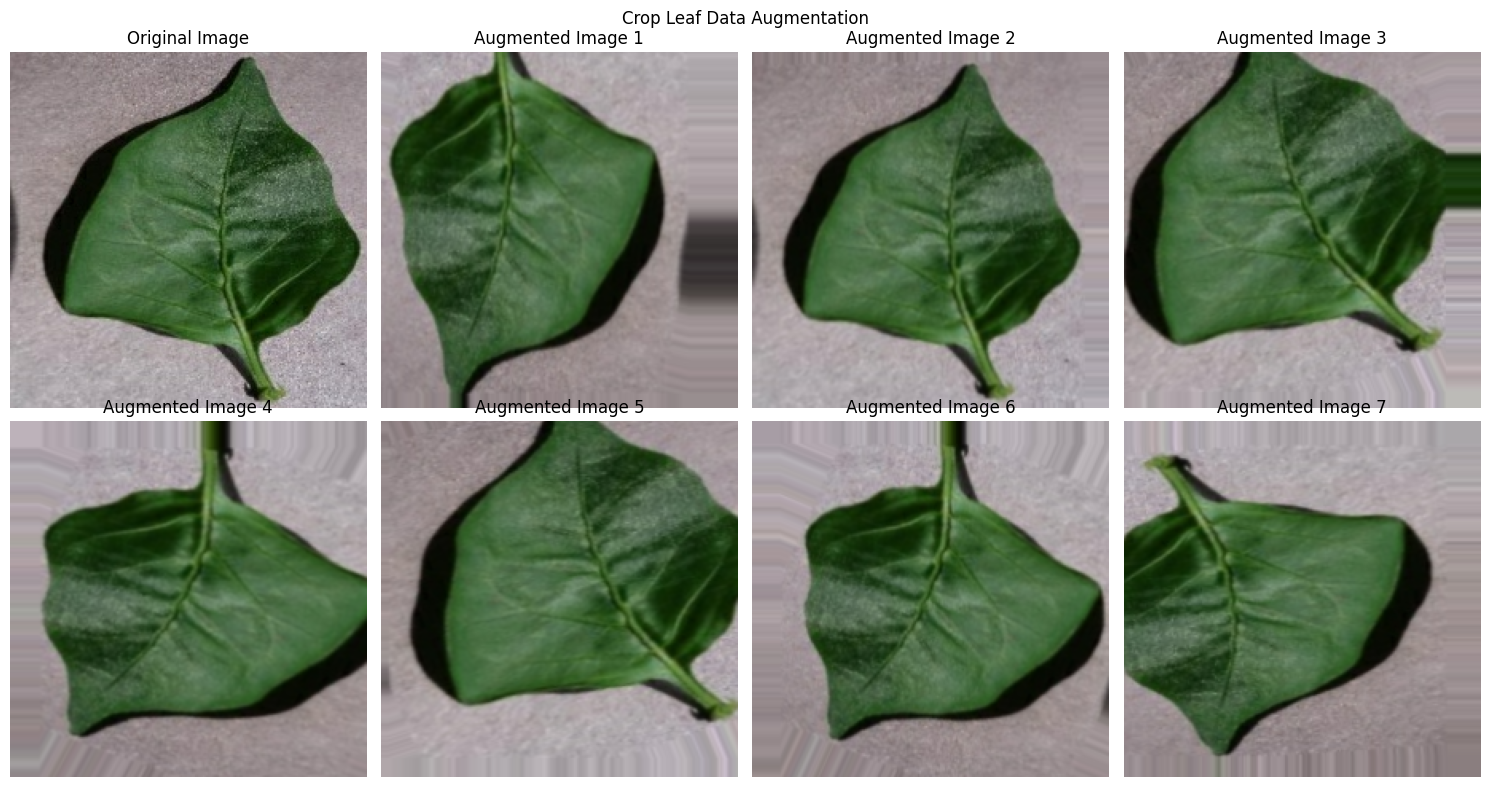

In [37]:

# PART 3 - CELL 3
# Visualize Original and Augmented Images

sample_images, sample_labels = next(iter(train_ds))

original_image = sample_images[0]

plt.figure(figsize=(15, 8))

plt.subplot(2, 4, 1)
plt.imshow(original_image.numpy())
plt.title("Original Image")
plt.axis("off")

for i in range(7):

    augmented_image = data_augmentation(
        tf.expand_dims(original_image, axis=0),
        training=True
    )

    augmented_image = tf.clip_by_value(
        augmented_image[0],
        0.0,
        1.0
    )

    plt.subplot(2, 4, i + 2)
    plt.imshow(augmented_image.numpy())
    plt.title(f"Augmented Image {i+1}")
    plt.axis("off")

plt.suptitle("Crop Leaf Data Augmentation")

plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULT_DIR,
        "data_augmentation_visualization.png"
    ),
    dpi=300
)

plt.show()


In [38]:

# PART 3 - CELL 4
# Verify training vs inference behavior

test_input = tf.expand_dims(
    original_image,
    axis=0
)

# Augmentation enabled
training_output = data_augmentation(
    test_input,
    training=True
)

# Augmentation disabled
inference_output = data_augmentation(
    test_input,
    training=False
)

print("Input Shape:", test_input.shape)
print("Training Output Shape:", training_output.shape)
print("Inference Output Shape:", inference_output.shape)

print(
    "Inference unchanged:",
    np.allclose(
        test_input.numpy(),
        inference_output.numpy()
    )
)

assert training_output.shape == (1, 224, 224, 3)
assert inference_output.shape == (1, 224, 224, 3)
assert np.allclose(test_input.numpy(), inference_output.numpy())

print("\nAugmentation behavior verified!")


Input Shape: (1, 224, 224, 3)
Training Output Shape: (1, 224, 224, 3)
Inference Output Shape: (1, 224, 224, 3)
Inference unchanged: True

Augmentation behavior verified!


In [39]:

# PART 3 - CELL 5
# CropNet-CNN Architecture Function

def build_cropnet_cnn(
    input_shape=(224, 224, 3),
    num_classes=15
):

    inputs = layers.Input(
        shape=input_shape,
        name="Leaf_Image_Input"
    )

    # Apply data augmentation only during training
    x = data_augmentation(inputs)

    # -------- Convolution Block 1 --------
    x = layers.Conv2D(
        32, (3, 3),
        padding="same",
        activation="relu",
        name="Block1_Conv1"
    )(x)

    x = layers.Conv2D(
        32, (3, 3),
        padding="same",
        activation="relu",
        name="Block1_Conv2"
    )(x)

    x = layers.BatchNormalization(
        name="Block1_BatchNorm"
    )(x)

    x = layers.MaxPooling2D(
        pool_size=(2, 2),
        name="Block1_MaxPool"
    )(x)

    # -------- Convolution Block 2 --------
    x = layers.Conv2D(
        64, (3, 3),
        padding="same",
        activation="relu",
        name="Block2_Conv1"
    )(x)

    x = layers.Conv2D(
        64, (3, 3),
        padding="same",
        activation="relu",
        name="Block2_Conv2"
    )(x)

    x = layers.BatchNormalization(
        name="Block2_BatchNorm"
    )(x)

    x = layers.MaxPooling2D(
        pool_size=(2, 2),
        name="Block2_MaxPool"
    )(x)

    x = layers.SpatialDropout2D(
        0.20,
        name="Block2_SpatialDropout"
    )(x)

    # -------- Convolution Block 3 --------
    x = layers.Conv2D(
        128, (3, 3),
        padding="same",
        activation="relu",
        name="Block3_Conv1"
    )(x)

    x = layers.Conv2D(
        128, (3, 3),
        padding="same",
        activation="relu",
        name="Block3_Conv2"
    )(x)

    x = layers.BatchNormalization(
        name="Block3_BatchNorm"
    )(x)

    x = layers.MaxPooling2D(
        pool_size=(2, 2),
        name="Block3_MaxPool"
    )(x)

    x = layers.SpatialDropout2D(
        0.25,
        name="Block3_SpatialDropout"
    )(x)

    # -------- Convolution Block 4 --------
    x = layers.Conv2D(
        256, (3, 3),
        padding="same",
        activation="relu",
        name="Block4_Conv1"
    )(x)

    x = layers.Conv2D(
        256, (3, 3),
        padding="same",
        activation="relu",
        name="Block4_Conv2"
    )(x)

    x = layers.BatchNormalization(
        name="Block4_BatchNorm"
    )(x)

    x = layers.MaxPooling2D(
        pool_size=(2, 2),
        name="Block4_MaxPool"
    )(x)

    x = layers.SpatialDropout2D(
        0.30,
        name="Block4_SpatialDropout"
    )(x)

    # -------- Convolution Block 5 --------
    x = layers.Conv2D(
        512, (3, 3),
        padding="same",
        activation="relu",
        name="Block5_Conv1"
    )(x)

    x = layers.BatchNormalization(
        name="Block5_BatchNorm"
    )(x)

    x = layers.MaxPooling2D(
        pool_size=(2, 2),
        name="Block5_MaxPool"
    )(x)

    x = layers.SpatialDropout2D(
        0.30,
        name="Block5_SpatialDropout"
    )(x)

    # -------- Global Average Pooling --------
    x = layers.GlobalAveragePooling2D(
        name="Global_Average_Pooling"
    )(x)

    # -------- Classifier Head --------
    x = layers.Dense(
        256,
        activation="relu",
        name="Dense_256"
    )(x)

    x = layers.BatchNormalization(
        name="Classifier_BatchNorm"
    )(x)

    x = layers.Dropout(
        0.50,
        name="Classifier_Dropout"
    )(x)

    # -------- Output Layer --------
    outputs = layers.Dense(
        num_classes,
        activation="softmax",
        name="Disease_Classification_Output"
    )(x)

    model = models.Model(
        inputs=inputs,
        outputs=outputs,
        name="CropNet_CNN"
    )

    return model


print("CropNet-CNN architecture function created!")


CropNet-CNN architecture function created!


In [40]:

# PART 3 - CELL 6
# Build CNN Model

cropnet_model = build_cropnet_cnn(
    input_shape=(224, 224, 3),
    num_classes=NUM_CLASSES
)

print("CropNet-CNN model created successfully!")

print("Model Name:", cropnet_model.name)
print("Input Shape:", cropnet_model.input_shape)
print("Output Shape:", cropnet_model.output_shape)


CropNet-CNN model created successfully!
Model Name: CropNet_CNN
Input Shape: (None, 224, 224, 3)
Output Shape: (None, 15)


In [41]:

# PART 3 - CELL 7
# Model Architecture Summary

cropnet_model.summary()

print("\nTotal Parameters:",
      cropnet_model.count_params())


Model: "CropNet_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Leaf_Image_Input (InputLayer)   │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Training_Data_Augmentation      │ (None, 224, 224, 3)    │             0 │
│ (Sequential)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block1_Conv1 (Conv2D)           │ (None, 224, 224, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block1_Conv2 (Conv2D)           │ (None, 224, 224, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block1_BatchNorm                │ (None, 224, 224, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block1_MaxPool (MaxPooling2D)   │ (None, 112, 112, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block2_Conv1 (Conv2D)           │ (None, 112, 112, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block2_Conv2 (Conv2D)           │ (None, 112, 112, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block2_BatchNorm                │ (None, 112, 112, 64)   │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block2_MaxPool (MaxPooling2D)   │ (None, 56, 56, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block2_SpatialDropout           │ (None, 56, 56, 64)     │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block3_Conv1 (Conv2D)           │ (None, 56, 56, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block3_Conv2 (Conv2D)           │ (None, 56, 56, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block3_BatchNorm                │ (None, 56, 56, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block3_MaxPool (MaxPooling2D)   │ (None, 28, 28, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block3_SpatialDropout           │ (None, 28, 28, 128)    │             0 │
│ (SpatialDropout2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block4_Conv1 (Conv2D)           │ (None, 28, 28, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block4_Conv2 (Conv2D)           │ (None, 28, 28, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block4_BatchNorm                │ (None, 28, 28, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block4_MaxPool (MaxPooling2D)   │ (None, 14, 14, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Block4_SpatialDropout           │ (None, 14, 14, 256)    │             0 │
│ (SpatialDropout2D)              │                        │             

 Total params: 2,492,591 (9.51 MB)

 Trainable params: 2,490,095 (9.50 MB)

 Non-trainable params: 2,496 (9.75 KB)


Total Parameters: 2492591


In [42]:

# PART 3 - CELL 8
# Parameter Analysis

total_params = cropnet_model.count_params()

trainable_params = sum(
    np.prod(variable.shape)
    for variable in cropnet_model.trainable_weights
)

non_trainable_params = sum(
    np.prod(variable.shape)
    for variable in cropnet_model.non_trainable_weights
)

print("Total Parameters:", total_params)

print("Trainable Parameters:", trainable_params)

print("Non-Trainable Parameters:", non_trainable_params)

print(
    "Parameter Verification:",
    trainable_params + non_trainable_params == total_params
)

assert trainable_params + non_trainable_params == total_params

print("\nParameter analysis completed!")


Total Parameters: 2492591
Trainable Parameters: 2490095
Non-Trainable Parameters: 2496
Parameter Verification: True

Parameter analysis completed!


In [43]:

# PART 3 - CELL 9
# Verify CNN Layer Output Shapes

layer_names = [
    "Block1_MaxPool",
    "Block2_MaxPool",
    "Block3_MaxPool",
    "Block4_MaxPool",
    "Block5_MaxPool",
    "Global_Average_Pooling",
    "Dense_256",
    "Disease_Classification_Output"
]

for name in layer_names:

    layer = cropnet_model.get_layer(name)

    print(
        name,
        "->",
        layer.output.shape
    )

print("\nArchitecture output shapes verified!")


Block1_MaxPool -> (None, 112, 112, 32)
Block2_MaxPool -> (None, 56, 56, 64)
Block3_MaxPool -> (None, 28, 28, 128)
Block4_MaxPool -> (None, 14, 14, 256)
Block5_MaxPool -> (None, 7, 7, 512)
Global_Average_Pooling -> (None, 512)
Dense_256 -> (None, 256)
Disease_Classification_Output -> (None, 15)

Architecture output shapes verified!


In [44]:

# PART 3 - CELL 10
# CNN Forward Propagation Test

sample_images, sample_labels = next(iter(train_ds))

predictions = cropnet_model(
    sample_images[:4],
    training=False
)

print("Input Batch Shape:", sample_images[:4].shape)

print("Output Prediction Shape:", predictions.shape)

print("\nPredicted Probabilities:")

print(predictions.numpy())

print(
    "\nProbability Sum:",
    tf.reduce_sum(predictions, axis=1).numpy()
)

assert predictions.shape == (4, NUM_CLASSES)

assert np.allclose(
    tf.reduce_sum(predictions, axis=1).numpy(),
    np.ones(4),
    atol=1e-5
)

print("\nForward propagation successful!")


Input Batch Shape: (4, 224, 224, 3)
Output Prediction Shape: (4, 15)

Predicted Probabilities:
[[0.06688401 0.0666315  0.06660119 0.06665213 0.06671825 0.06681085
  0.06665248 0.06662313 0.06648062 0.06661802 0.06663968 0.06676222
  0.06671836 0.06659201 0.06661553]
 [0.06689247 0.06663883 0.06659988 0.06664716 0.06669912 0.06680095
  0.06666069 0.0666143  0.06649455 0.06661503 0.06663393 0.06674969
  0.06671726 0.0666125  0.06662362]
 [0.06672806 0.06664632 0.06664565 0.06667172 0.06669109 0.0667127
  0.06667081 0.06664646 0.06659462 0.06667022 0.06666651 0.06668939
  0.06667409 0.06664537 0.06664699]
 [0.06688648 0.06663952 0.066608   0.06665125 0.06671452 0.06681599
  0.0666547  0.06662007 0.06647781 0.06661931 0.06663592 0.06676012
  0.06671714 0.0665849  0.06661425]]

Probability Sum: [0.99999994 1.         1.         1.        ]

Forward propagation successful!


In [45]:

# PART 3 - CELL 11
# Compile CropNet-CNN

optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.001,
    beta_1=0.9,
    beta_2=0.999,
    epsilon=1e-7
)

cropnet_model.compile(
    optimizer=optimizer,
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("CropNet-CNN compiled successfully!")

print("Optimizer: Adam")
print("Learning Rate: 0.001")
print("Beta 1: 0.9")
print("Beta 2: 0.999")
print("Epsilon: 1e-7")
print("Loss: Categorical Crossentropy")
print("Metric: Accuracy")


CropNet-CNN compiled successfully!
Optimizer: Adam
Learning Rate: 0.001
Beta 1: 0.9
Beta 2: 0.999
Epsilon: 1e-7
Loss: Categorical Crossentropy
Metric: Accuracy


In [46]:

# PART 3 - CELL 12
# Save CNN Architecture Diagram

try:

    tf.keras.utils.plot_model(
        cropnet_model,
        to_file=os.path.join(
            RESULT_DIR,
            "CropNet_CNN_Architecture.png"
        ),
        show_shapes=True,
        show_layer_names=True,
        expand_nested=True,
        dpi=120
    )

    print("Architecture diagram saved successfully!")

except Exception as e:

    print("Diagram generation unavailable:", e)
    print("Model summary is available as an alternative.")



Architecture diagram saved successfully!


In [47]:

# PART 3 - CELL 13
# Save CNN Architecture Configuration

architecture_json = cropnet_model.to_json()

architecture_path = os.path.join(
    MODEL_DIR,
    "CropNet_CNN_Architecture.json"
)

with open(architecture_path, "w") as f:
    f.write(architecture_json)

print("Architecture saved:", architecture_path)

print("Model Name:", cropnet_model.name)
print("Input Shape:", cropnet_model.input_shape)
print("Output Shape:", cropnet_model.output_shape)
print("Parameters:", cropnet_model.count_params())

print("\nCropNet-CNN configuration saved!")


Architecture saved: /content/Crop_Disease_Project/models/CropNet_CNN_Architecture.json
Model Name: CropNet_CNN
Input Shape: (None, 224, 224, 3)
Output Shape: (None, 15)
Parameters: 2492591

CropNet-CNN configuration saved!


In [48]:

# PART 4 - CELL 1
# Verify GPU and TensorFlow Environment

import tensorflow as tf
import os
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import json

print("TensorFlow Version:", tf.__version__)

gpus = tf.config.list_physical_devices("GPU")

print("\nAvailable GPUs:", gpus)

if gpus:
    print("\nSUCCESS: GPU detected!")

    for gpu in gpus:
        print(gpu)

else:
    print("\nWARNING: GPU unavailable.")
    print("Training will run on CPU.")

print("\nTraining Dataset:", len(X_train))
print("Validation Dataset:", len(X_val))
print("Testing Dataset:", len(X_test))


TensorFlow Version: 2.21.0

Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

SUCCESS: GPU detected!
PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')

Training Dataset: 14447
Validation Dataset: 3095
Testing Dataset: 3096


In [49]:

# PART 4 - CELL 2
# Training Configuration

EPOCHS = 35
BATCH_SIZE = 32

INITIAL_LEARNING_RATE = 0.001

REDUCE_LR_FACTOR = 0.5
REDUCE_LR_PATIENCE = 3

EARLY_STOPPING_PATIENCE = 7

MONITOR_METRIC = "val_loss"

print("========== TRAINING CONFIGURATION ==========")

print("Model:", cropnet_model.name)
print("Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)
print("Learning Rate:", INITIAL_LEARNING_RATE)
print("Optimizer: Adam")
print("Loss: Categorical Crossentropy")
print("Reduce LR Factor:", REDUCE_LR_FACTOR)
print("Reduce LR Patience:", REDUCE_LR_PATIENCE)
print("Early Stopping Patience:", EARLY_STOPPING_PATIENCE)

assert NUM_CLASSES == 15
assert BATCH_SIZE == 32
assert EPOCHS == 35

print("\nConfiguration verified!")


========== TRAINING CONFIGURATION ==========
Model: CropNet_CNN
Epochs: 35
Batch Size: 32
Learning Rate: 0.001
Optimizer: Adam
Loss: Categorical Crossentropy
Reduce LR Factor: 0.5
Reduce LR Patience: 3
Early Stopping Patience: 7

Configuration verified!


In [50]:

# PART 4 - CELL 3
# Compile Model for Training

optimizer = tf.keras.optimizers.Adam(
    learning_rate=INITIAL_LEARNING_RATE,
    beta_1=0.9,
    beta_2=0.999,
    epsilon=1e-7
)

cropnet_model.compile(
    optimizer=optimizer,
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("CropNet-CNN compiled successfully!")

print("Optimizer: Adam")
print("Learning Rate:", INITIAL_LEARNING_RATE)
print("Loss: Categorical Crossentropy")
print("Metric: Accuracy")


CropNet-CNN compiled successfully!
Optimizer: Adam
Learning Rate: 0.001
Loss: Categorical Crossentropy
Metric: Accuracy


In [51]:

# PART 4 - CELL 4
# ModelCheckpoint Callback

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "CropNet_CNN_Best.keras"
)

checkpoint_callback = tf.keras.callbacks.ModelCheckpoint(
    filepath=BEST_MODEL_PATH,
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=False,
    mode="min",
    verbose=1
)

print("ModelCheckpoint configured!")
print("Best Model Path:", BEST_MODEL_PATH)


ModelCheckpoint configured!
Best Model Path: /content/Crop_Disease_Project/models/CropNet_CNN_Best.keras


In [52]:

# PART 4 - CELL 5
# ReduceLROnPlateau Callback

reduce_lr_callback = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=REDUCE_LR_FACTOR,
    patience=REDUCE_LR_PATIENCE,
    min_lr=1e-7,
    mode="min",
    verbose=1
)

print("ReduceLROnPlateau configured!")
print("Factor:", REDUCE_LR_FACTOR)
print("Patience:", REDUCE_LR_PATIENCE)


ReduceLROnPlateau configured!
Factor: 0.5
Patience: 3


In [53]:

# PART 4 - CELL 6
# EarlyStopping Callback

early_stopping_callback = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOPPING_PATIENCE,
    mode="min",
    restore_best_weights=True,
    verbose=1
)

print("EarlyStopping configured!")
print("Patience:", EARLY_STOPPING_PATIENCE)
print("Restore Best Weights: True")


EarlyStopping configured!
Patience: 7
Restore Best Weights: True


In [54]:

# PART 4 - CELL 7
# Combine All Training Callbacks

training_callbacks = [
    checkpoint_callback,
    reduce_lr_callback,
    early_stopping_callback
]

print("Total Callbacks:", len(training_callbacks))

for callback in training_callbacks:
    print(type(callback).__name__)

print("\nAll training callbacks ready!")


Total Callbacks: 3
ModelCheckpoint
ReduceLROnPlateau
EarlyStopping

All training callbacks ready!


In [55]:

# PART 4 - CELL 8
# Verify Training Dataset

train_images, train_labels = next(iter(train_ds))

val_images, val_labels = next(iter(val_ds))

print("========== TRAINING DATA ==========")

print("Image Shape:", train_images.shape)
print("Label Shape:", train_labels.shape)

print("\n========== VALIDATION DATA ==========")

print("Image Shape:", val_images.shape)
print("Label Shape:", val_labels.shape)

assert train_images.shape[1:] == (224, 224, 3)
assert val_images.shape[1:] == (224, 224, 3)

assert train_labels.shape[-1] == 15
assert val_labels.shape[-1] == 15

print("\nTraining and validation datasets verified!")


========== TRAINING DATA ==========
Image Shape: (32, 224, 224, 3)
Label Shape: (32, 15)

========== VALIDATION DATA ==========
Image Shape: (32, 224, 224, 3)
Label Shape: (32, 15)

Training and validation datasets verified!


In [56]:

# PART 4 - CELL 9
# START CROPNet-CNN TRAINING

print("=" * 60)
print("STARTING CROPNET-CNN TRAINING")
print("=" * 60)

print("Training Samples:", len(X_train))
print("Validation Samples:", len(X_val))
print("Maximum Epochs:", EPOCHS)
print("Batch Size:", BATCH_SIZE)

# Start training
history = cropnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=training_callbacks,
    verbose=1
)

print("\n" + "=" * 60)
print("CROPNET-CNN TRAINING COMPLETED")
print("=" * 60)

print("Completed Epochs:", len(history.history["loss"]))
print("Best Validation Accuracy:",
      max(history.history["val_accuracy"]))

print("Best Validation Loss:",
      min(history.history["val_loss"]))


STARTING CROPNET-CNN TRAINING
Training Samples: 14447
Validation Samples: 3095
Maximum Epochs: 35
Batch Size: 32
Epoch 1/35
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 277ms/step - accuracy: 0.3694 - loss: 2.2876
Epoch 1: val_loss improved from None to 3.76258, saving model to /content/Crop_Disease_Project/models/CropNet_CNN_Best.keras

Epoch 1: finished saving model to /content/Crop_Disease_Project/models/CropNet_CNN_Best.keras
452/452 ━━━━━━━━━━━━━━━━━━━━ 155s 294ms/step - accuracy: 0.4748 - loss: 1.7771 - val_accuracy: 0.1832 - val_loss: 3.7626 - learning_rate: 0.0010
Epoch 2/35
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 266ms/step - accuracy: 0.6293 - loss: 1.1289
Epoch 2: val_loss did not improve from 3.76258
452/452 ━━━━━━━━━━━━━━━━━━━━ 125s 277ms/step - accuracy: 0.6477 - loss: 1.0694 - val_accuracy: 0.2346 - val_loss: 4.1723 - learning_rate: 0.0010
Epoch 3/35
452/452 ━━━━━━━━━━━━━━━━━━━━ 0s 267ms/step - accuracy: 0.7077 - loss: 0.8815
Epoch 3: val_loss improved from 3.76258 to 1.07373, saving model t

In [57]:

# PART 4 - CELL 10
# Extract Training History

history_df = pd.DataFrame(history.history)

print("Training History:")
display(history_df)

print("\nTotal Epochs:", len(history_df))

print("Final Training Accuracy:",
      history.history["accuracy"][-1])

print("Final Validation Accuracy:",
      history.history["val_accuracy"][-1])

print("Final Training Loss:",
      history.history["loss"][-1])

print("Final Validation Loss:",
      history.history["val_loss"][-1])

history_df.to_csv(
    os.path.join(RESULT_DIR, "training_history.csv"),
    index=False
)

print("\nTraining history saved!")


Training History:


,accuracy,loss,val_accuracy,val_loss,learning_rate
0,0.474770,1.777130,0.183199,3.762584,0.001000
1,0.647747,1.069401,0.234572,4.172345,0.001000
2,0.713505,0.854497,0.666236,1.073726,0.001000
3,0.744030,0.759789,0.539580,1.893618,0.001000
4,0.775040,0.674260,0.398061,2.949831,0.001000
5,0.791029,0.623584,0.727302,0.901895,0.001000
6,0.805011,0.571886,0.394507,3.156997,0.001000
7,0.827300,0.520556,0.810016,0.587138,0.001000
8,0.839759,0.478289,0.323748,4.647588,0.001000
9,0.854641,0.426897,0.393538,3.532231,0.001000



Total Epochs: 26
Final Training Accuracy: 0.9465633034706116
Final Validation Accuracy: 0.9046849608421326
Final Training Loss: 0.15995782613754272
Final Validation Loss: 0.32956966757774353

Training history saved!


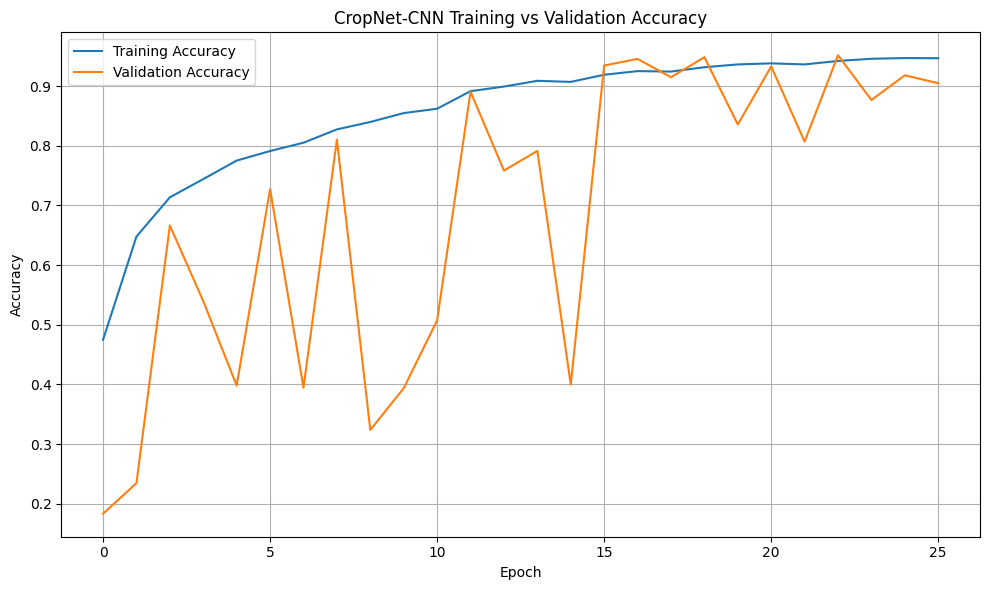

Accuracy graph saved!


In [58]:

# PART 4 - CELL 11
# Training and Validation Accuracy Graph

plt.figure(figsize=(10, 6))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("CropNet-CNN Training vs Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULT_DIR,
        "training_validation_accuracy.png"
    ),
    dpi=300
)

plt.show()

print("Accuracy graph saved!")


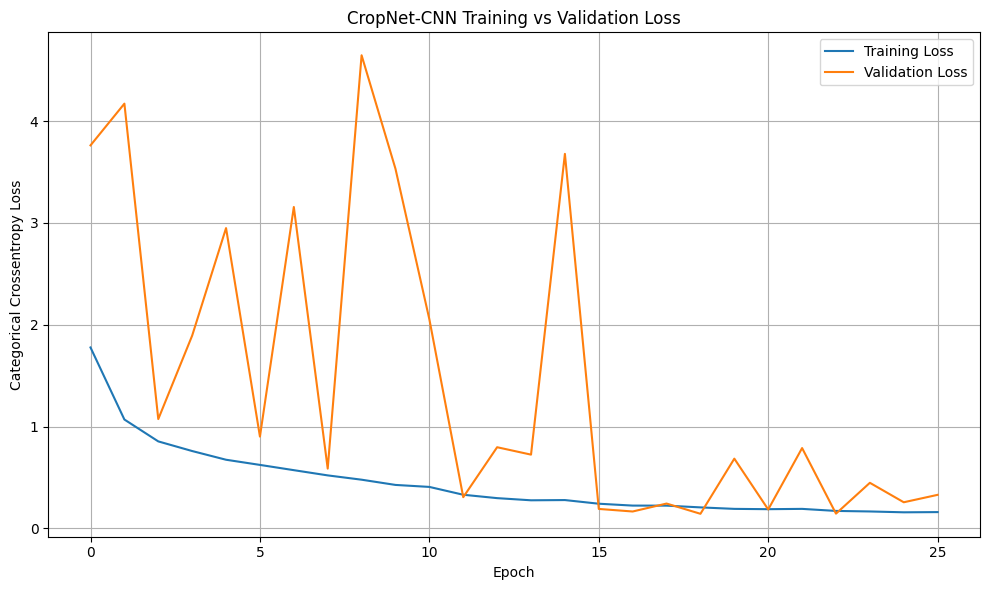

Loss graph saved!


In [59]:

# PART 4 - CELL 12
# Training and Validation Loss Graph

plt.figure(figsize=(10, 6))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("CropNet-CNN Training vs Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Categorical Crossentropy Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULT_DIR,
        "training_validation_loss.png"
    ),
    dpi=300
)

plt.show()

print("Loss graph saved!")


In [60]:

# PART 4 - CELL 13
# Learning Rate History

learning_rates = [
    float(tf.keras.backend.get_value(
        cropnet_model.optimizer.learning_rate
    ))
]

# Note:
# This is the final learning rate.
# Exact epoch-wise learning rates are recorded
# using a callback in the next cell if training is rerun.
print("Final Learning Rate:", learning_rates[-1])


Final Learning Rate: 6.25000029685907e-05


In [61]:

# OPTIONAL - EPOCH-WISE LEARNING RATE LOGGER

class LearningRateLogger(tf.keras.callbacks.Callback):

    def on_epoch_end(self, epoch, logs=None):

        current_lr = float(
            tf.keras.backend.get_value(
                self.model.optimizer.learning_rate
            )
        )

        print(
            f"Epoch {epoch + 1}: Learning Rate = {current_lr:.8f}"
        )


In [62]:

# PART 4 - CELL 14
# Load Best Model Checkpoint

assert os.path.exists(BEST_MODEL_PATH), (
    "Best model checkpoint not found!"
)

best_model = tf.keras.models.load_model(
    BEST_MODEL_PATH
)

print("Best checkpoint loaded successfully!")

print("Model:", best_model.name)
print("Input Shape:", best_model.input_shape)
print("Output Shape:", best_model.output_shape)
print("Parameters:", best_model.count_params())


Best checkpoint loaded successfully!
Model: CropNet_CNN
Input Shape: (None, 224, 224, 3)
Output Shape: (None, 15)
Parameters: 2492591


In [63]:

# PART 4 - CELL 15
# Save Final Trained CropNet-CNN Model

FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "CropNet_CNN_Final.keras"
)

best_model.save(FINAL_MODEL_PATH)

print("Final trained model saved successfully!")
print("Location:", FINAL_MODEL_PATH)

print("File Size:",
      round(os.path.getsize(FINAL_MODEL_PATH) / (1024 * 1024), 2),
      "MB")


Final trained model saved successfully!
Location: /content/Crop_Disease_Project/models/CropNet_CNN_Final.keras
File Size: 28.65 MB


In [64]:

# PART 4 - CELL 16
# Reload Final Model and Verify

loaded_model = tf.keras.models.load_model(
    FINAL_MODEL_PATH
)

# Test one batch
sample_images, sample_labels = next(iter(val_ds))

sample_predictions = loaded_model.predict(
    sample_images[:4],
    verbose=0
)

print("Reloaded Model:", loaded_model.name)

print("Prediction Shape:", sample_predictions.shape)

print("Predicted Probabilities:")
print(sample_predictions)

assert sample_predictions.shape == (4, 15)

assert np.allclose(
    sample_predictions.sum(axis=1),
    1.0,
    atol=1e-5
)

print("\nSUCCESS: Saved model is working correctly!")


Reloaded Model: CropNet_CNN
Prediction Shape: (4, 15)
Predicted Probabilities:
[[5.6313831e-07 6.8461901e-07 7.7317059e-09 8.7288676e-08 2.6346731e-07
  5.3495995e-05 3.0918144e-07 2.1695837e-06 7.6922312e-08 4.7391183e-08
  4.1630312e-07 2.3938798e-08 9.9994123e-01 3.1086344e-07 2.2815074e-07]
 [3.8265817e-02 4.9877499e-04 4.6548925e-04 3.9314334e-03 4.8258655e-05
  4.7054104e-04 1.3692501e-01 7.9140687e-01 3.0413694e-03 2.3718963e-03
  4.5302222e-05 4.6265788e-05 2.2400593e-02 8.1385435e-05 1.1313773e-06]
 [2.0013957e-03 8.5714655e-06 4.4001546e-05 5.9995534e-07 1.6589144e-07
  7.5339790e-07 4.7940644e-03 8.9384848e-06 1.1046645e-03 9.9201411e-01
  3.8978467e-08 3.2841294e-06 5.0831304e-08 1.9401225e-05 1.7881044e-08]
 [6.6488715e-06 6.3740081e-05 8.4251369e-06 1.4354607e-05 7.2853331e-04
  2.4568131e-05 4.6965724e-06 5.1679908e-05 4.0958941e-05 7.1089369e-07
  2.5127184e-01 1.4735250e-03 1.2435412e-04 4.9116922e-04 7.4569482e-01]]

SUCCESS: Saved model is working correctly!


In [65]:

# PART 4 - CELL 17
# Save Training Metadata

training_metadata = {

    "model_name": "CropNet-CNN",

    "epochs_requested": EPOCHS,

    "epochs_completed": len(history.history["loss"]),

    "batch_size": BATCH_SIZE,

    "optimizer": "Adam",

    "learning_rate_initial": INITIAL_LEARNING_RATE,

    "beta_1": 0.9,

    "beta_2": 0.999,

    "epsilon": 1e-7,

    "loss": "Categorical Crossentropy",

    "reduce_lr_factor": REDUCE_LR_FACTOR,

    "reduce_lr_patience": REDUCE_LR_PATIENCE,

    "early_stopping_patience": EARLY_STOPPING_PATIENCE,

    "training_images": len(X_train),

    "validation_images": len(X_val),

    "testing_images": len(X_test),

    "number_of_classes": NUM_CLASSES,

    "best_validation_accuracy": float(
        max(history.history["val_accuracy"])
    ),

    "best_validation_loss": float(
        min(history.history["val_loss"])
    ),

    "final_model": FINAL_MODEL_PATH

}

metadata_path = os.path.join(
    RESULT_DIR,
    "training_metadata.json"
)

with open(metadata_path, "w") as f:

    json.dump(
        training_metadata,
        f,
        indent=4
    )

print("Training metadata saved successfully!")

print(json.dumps(training_metadata, indent=4))


Training metadata saved successfully!
{
    "model_name": "CropNet-CNN",
    "epochs_requested": 35,
    "epochs_completed": 26,
    "batch_size": 32,
    "optimizer": "Adam",
    "learning_rate_initial": 0.001,
    "beta_1": 0.9,
    "beta_2": 0.999,
    "epsilon": 1e-07,
    "loss": "Categorical Crossentropy",
    "reduce_lr_factor": 0.5,
    "reduce_lr_patience": 3,
    "early_stopping_patience": 7,
    "training_images": 14447,
    "validation_images": 3095,
    "testing_images": 3096,
    "number_of_classes": 15,
    "best_validation_accuracy": 0.9515347480773926,
    "best_validation_loss": 0.14331327378749847,
    "final_model": "/content/Crop_Disease_Project/models/CropNet_CNN_Final.keras"
}


In [66]:

# PART 5 - CELL 1
# Import Evaluation Libraries

import os
import json
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from PIL import Image

print("TensorFlow Version:", tf.__version__)
print("Evaluation libraries imported successfully!")


TensorFlow Version: 2.21.0
Evaluation libraries imported successfully!


In [67]:

# PART 5 - CELL 2
# Load Best Trained Model

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "CropNet_CNN_Best.keras"
)

assert os.path.exists(BEST_MODEL_PATH), (
    "Best model not found! Complete Part 4 first."
)

evaluation_model = tf.keras.models.load_model(
    BEST_MODEL_PATH
)

print("Best CropNet-CNN model loaded successfully!")

print("Model Name:", evaluation_model.name)
print("Input Shape:", evaluation_model.input_shape)
print("Output Shape:", evaluation_model.output_shape)
print("Total Parameters:", evaluation_model.count_params())

assert evaluation_model.output_shape[-1] == 15

print("\nModel is ready for evaluation!")


Best CropNet-CNN model loaded successfully!
Model Name: CropNet_CNN
Input Shape: (None, 224, 224, 3)
Output Shape: (None, 15)
Total Parameters: 2492591

Model is ready for evaluation!


In [68]:

# PART 5 - CELL 3
# Verify Unseen Test Dataset

print("========== TEST DATASET ==========")

print("Total Test Images:", len(X_test))
print("Number of Classes:", len(selected_classes))

print("Testing Dataset Shape:", test_df.shape)

print("\nClass Distribution:")

test_distribution = (
    pd.Series(y_test)
    .value_counts()
    .sort_index()
)

for i, class_name in enumerate(selected_classes):

    print(
        f"{class_name}:",
        int(test_distribution.get(i, 0))
    )

assert len(X_test) > 0
assert len(np.unique(y_test)) == 15

print("\nAll 15 classes are present in test data!")

if len(X_test) == 3096:
    print("SRS test image count matched: 3096")
else:
    print(
        "NOTE: Actual test image count differs from SRS:",
        len(X_test)
    )


========== TEST DATASET ==========
Total Test Images: 3096
Number of Classes: 15
Testing Dataset Shape: (3096, 2)

Class Distribution:
Pepper__bell___Bacterial_spot: 149
Pepper__bell___healthy: 221
Potato___Early_blight: 150
Potato___Late_blight: 150
Potato___healthy: 23
Tomato_Bacterial_spot: 319
Tomato_Early_blight: 150
Tomato_Late_blight: 287
Tomato_Leaf_Mold: 143
Tomato_Septoria_leaf_spot: 266
Tomato_Spider_mites_Two_spotted_spider_mite: 252
Tomato__Target_Spot: 210
Tomato__Tomato_YellowLeaf__Curl_Virus: 481
Tomato__Tomato_mosaic_virus: 56
Tomato_healthy: 239

All 15 classes are present in test data!
SRS test image count matched: 3096


In [69]:

# PART 5 - CELL 4
# Evaluate Model on Test Dataset

test_results = evaluation_model.evaluate(
    test_ds,
    verbose=1
)

test_loss = test_results[0]
test_accuracy = test_results[1]

print("\n========== TEST RESULTS ==========")

print("Test Loss:", round(float(test_loss), 4))

print(
    "Test Accuracy:",
    round(float(test_accuracy) * 100, 2),
    "%"
)

if test_accuracy >= 0.94:
    print("SUCCESS: SRS accuracy target achieved!")
else:
    print("SRS accuracy target not achieved yet.")

print("\nTest evaluation completed!")


97/97 ━━━━━━━━━━━━━━━━━━━━ 8s 72ms/step - accuracy: 0.9548 - loss: 0.1487

========== TEST RESULTS ==========
Test Loss: 0.1487
Test Accuracy: 95.48 %
SUCCESS: SRS accuracy target achieved!

Test evaluation completed!


In [70]:

# PART 5 - CELL 5
# Generate Predictions for All Test Images

y_prob = evaluation_model.predict(
    test_ds,
    verbose=1
)

# Convert probabilities into predicted class indices
y_pred = np.argmax(y_prob, axis=1)

# Convert actual labels into integer format
y_true = np.asarray(y_test).astype(int)

print("Actual Labels Shape:", y_true.shape)
print("Predicted Labels Shape:", y_pred.shape)
print("Prediction Probability Shape:", y_prob.shape)

assert y_pred.shape == y_true.shape
assert y_prob.shape == (len(y_true), 15)

print("\nAll test predictions generated successfully!")


97/97 ━━━━━━━━━━━━━━━━━━━━ 6s 54ms/step
Actual Labels Shape: (3096,)
Predicted Labels Shape: (3096,)
Prediction Probability Shape: (3096, 15)

All test predictions generated successfully!


In [71]:

# PART 5 - CELL 6
# Calculate Classification Metrics

test_accuracy_manual = accuracy_score(
    y_true,
    y_pred
)

macro_precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

macro_recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

weighted_precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

weighted_recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

weighted_f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

print("========== CLASSIFICATION METRICS ==========")

print("Test Accuracy:", round(test_accuracy_manual * 100, 2), "%")

print("Macro Precision:", round(macro_precision, 4))
print("Macro Recall:", round(macro_recall, 4))
print("Macro F1-Score:", round(macro_f1, 4))

print("\nWeighted Precision:", round(weighted_precision, 4))
print("Weighted Recall:", round(weighted_recall, 4))
print("Weighted F1-Score:", round(weighted_f1, 4))


========== CLASSIFICATION METRICS ==========
Test Accuracy: 95.48 %
Macro Precision: 0.9452
Macro Recall: 0.9518
Macro F1-Score: 0.9471

Weighted Precision: 0.9565
Weighted Recall: 0.9548
Weighted F1-Score: 0.9544


In [72]:

# PART 5 - CELL 7
# Complete Classification Report

class_report = classification_report(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    target_names=selected_classes,
    output_dict=True,
    zero_division=0
)

classification_df = pd.DataFrame(
    class_report
).transpose()

print("========== COMPLETE CLASSIFICATION REPORT ==========")

display(
    classification_df.round(4)
)

classification_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "classification_report.csv"
    )
)

print("\nClassification report saved successfully!")


========== COMPLETE CLASSIFICATION REPORT ==========


,precision,recall,f1-score,support
Pepper__bell___Bacterial_spot,0.9728,0.9597,0.9662,149.0000
Pepper__bell___healthy,0.9777,0.9910,0.9843,221.0000
Potato___Early_blight,0.9308,0.9867,0.9579,150.0000
Potato___Late_blight,0.9145,0.9267,0.9205,150.0000
Potato___healthy,0.9524,0.8696,0.9091,23.0000
Tomato_Bacterial_spot,0.9461,0.9906,0.9678,319.0000
Tomato_Early_blight,0.8571,0.9200,0.8875,150.0000
Tomato_Late_blight,0.9874,0.8223,0.8973,287.0000
Tomato_Leaf_Mold,0.9793,0.9930,0.9861,143.0000
Tomato_Septoria_leaf_spot,0.9258,0.9850,0.9545,266.0000



Classification report saved successfully!


In [73]:

# PART 5 - CELL 8
# Generate Confusion Matrix

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES)
)

print("Confusion Matrix Shape:", cm.shape)

print("\nConfusion Matrix:")

print(cm)

assert cm.shape == (15, 15)

print("\n15 x 15 confusion matrix generated!")


Confusion Matrix Shape: (15, 15)

Confusion Matrix:
[[143   2   0   0   0   1   0   0   0   3   0   0   0   0   0]
 [  0 219   0   0   1   0   0   1   0   0   0   0   0   0   0]
 [  0   0 148   0   0   0   1   0   0   1   0   0   0   0   0]
 [  2   0   5 139   0   0   0   0   0   4   0   0   0   0   0]
 [  0   1   0   0  20   0   0   0   0   0   2   0   0   0   0]
 [  0   0   0   0   0 316   1   0   0   1   0   1   0   0   0]
 [  0   0   1   1   0   3 138   2   0   2   0   1   2   0   0]
 [  0   1   4  12   0   5  21 236   0   7   0   0   0   0   1]
 [  0   0   0   0   0   0   0   0 142   0   1   0   0   0   0]
 [  1   0   1   0   0   0   0   0   0 262   0   1   0   1   0]
 [  0   0   0   0   0   0   0   0   2   0 231   2   0   8   9]
 [  0   0   0   0   0   0   0   0   1   3   4 198   0   1   3]
 [  1   0   0   0   0   9   0   0   0   0   1   0 470   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0   0   0  56   0]
 [  0   1   0   0   0   0   0   0   0   0   0   0   0   0 238]]

1

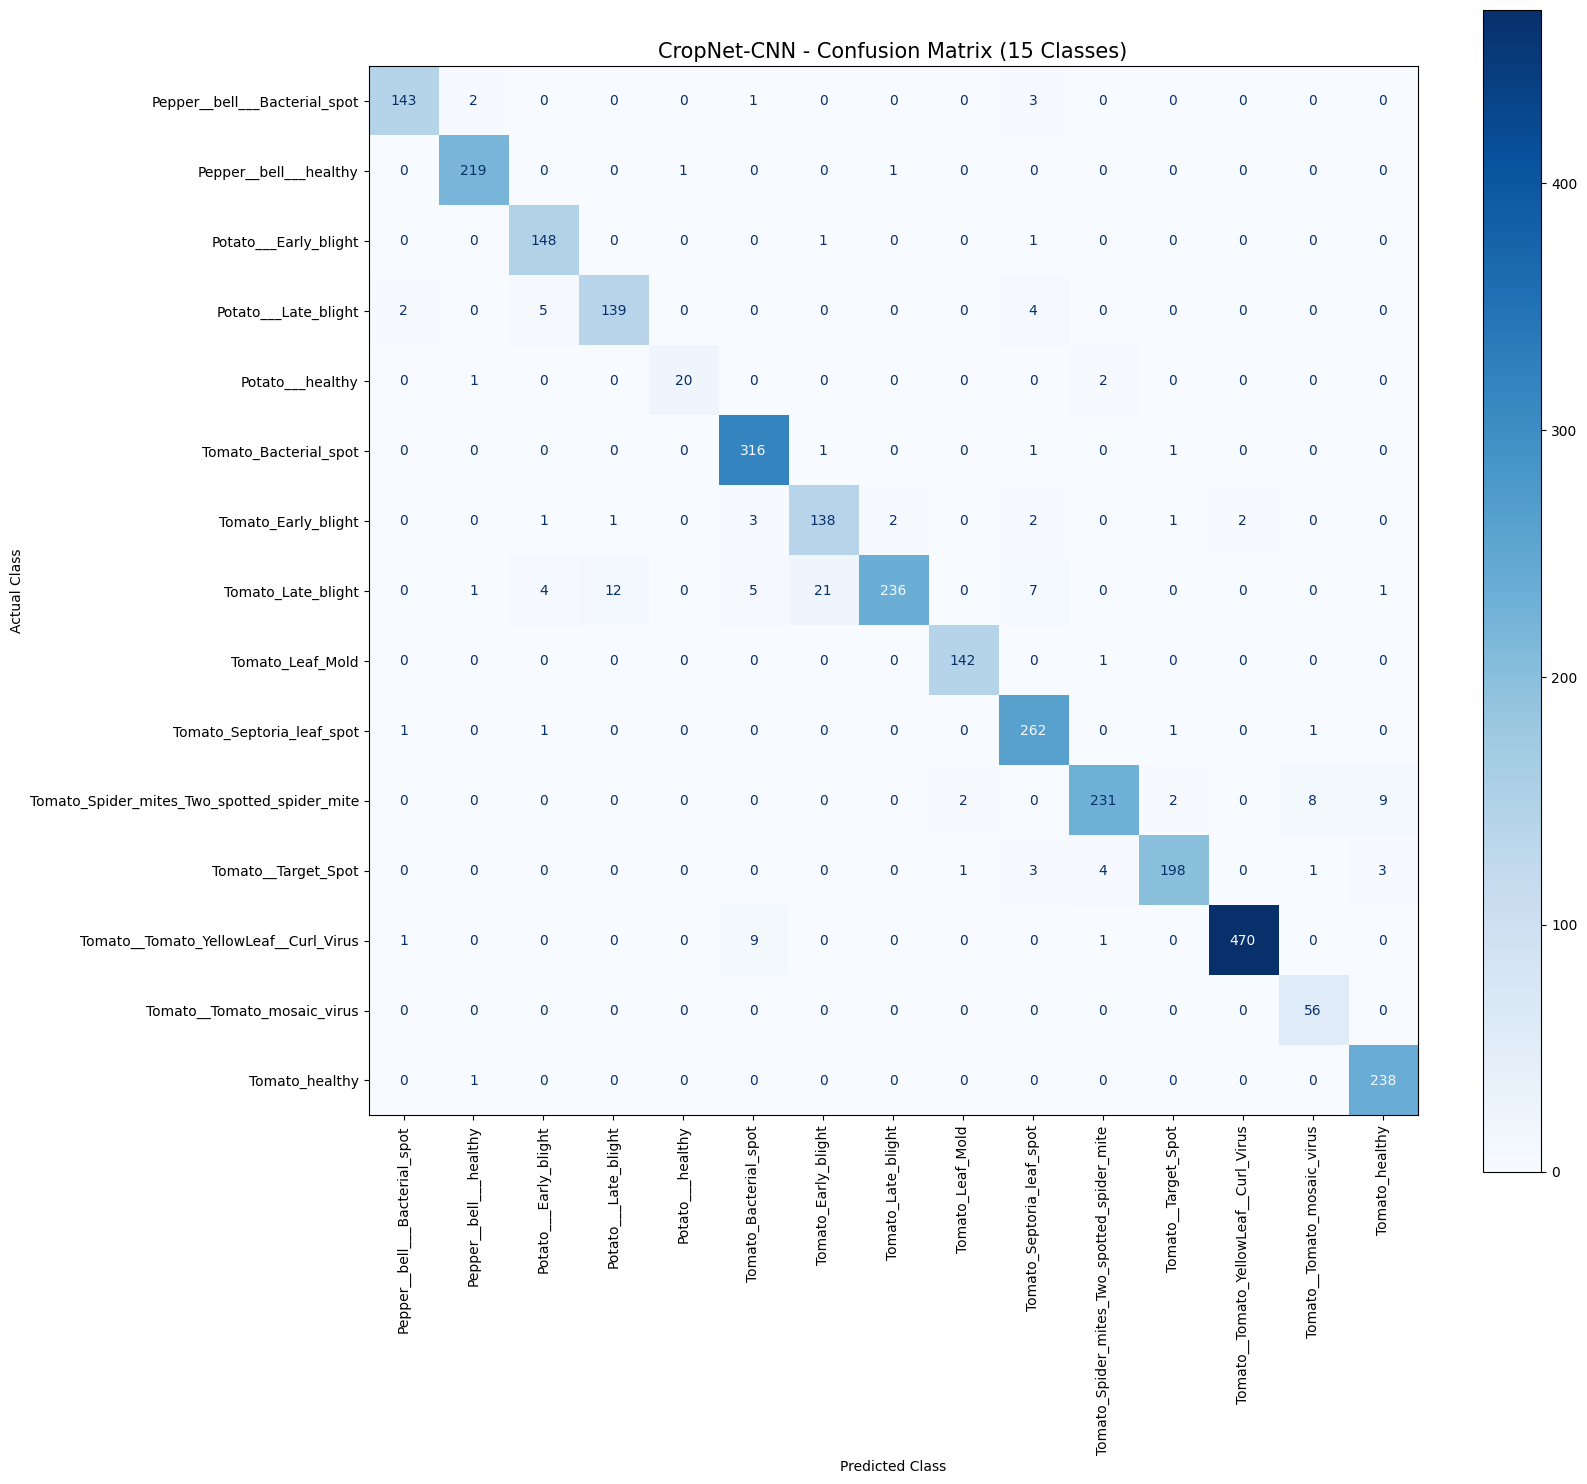

Confusion matrix visualization saved!


In [74]:

# PART 5 - CELL 9
# Plot Confusion Matrix

fig, ax = plt.subplots(figsize=(17, 15))

display_matrix = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=selected_classes
)

display_matrix.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    values_format="d",
    colorbar=True
)

plt.title(
    "CropNet-CNN - Confusion Matrix (15 Classes)",
    fontsize=15
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULT_DIR,
        "confusion_matrix_15_classes.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix visualization saved!")


In [75]:

# PART 5 - CELL 10
# Per-Class Performance Analysis

per_class_precision = precision_score(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    average=None,
    zero_division=0
)

per_class_recall = recall_score(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    average=None,
    zero_division=0
)

per_class_f1 = f1_score(
    y_true,
    y_pred,
    labels=np.arange(NUM_CLASSES),
    average=None,
    zero_division=0
)

support = np.bincount(
    y_true,
    minlength=NUM_CLASSES
)

per_class_df = pd.DataFrame({
    "Class": selected_classes,
    "Precision": per_class_precision,
    "Recall": per_class_recall,
    "F1_Score": per_class_f1,
    "Support": support
})

per_class_df = per_class_df.sort_values(
    by="F1_Score",
    ascending=False
)

display(per_class_df.round(4))

print("\nBest Performing Class:")
print(per_class_df.iloc[0]["Class"])

print("\nLowest Performing Class:")
print(per_class_df.iloc[-1]["Class"])

per_class_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "per_class_performance.csv"
    ),
    index=False
)

print("\nPer-class analysis saved!")


,Class,Precision,Recall,F1_Score,Support
12,Tomato__Tomato_YellowLeaf__Curl_Virus,0.9958,0.9771,0.9864,481
8,Tomato_Leaf_Mold,0.9793,0.9930,0.9861,143
1,Pepper__bell___healthy,0.9777,0.9910,0.9843,221
14,Tomato_healthy,0.9482,0.9958,0.9714,239
5,Tomato_Bacterial_spot,0.9461,0.9906,0.9678,319
0,Pepper__bell___Bacterial_spot,0.9728,0.9597,0.9662,149
11,Tomato__Target_Spot,0.9754,0.9429,0.9588,210
2,Potato___Early_blight,0.9308,0.9867,0.9579,150
9,Tomato_Septoria_leaf_spot,0.9258,0.9850,0.9545,266
10,Tomato_Spider_mites_Two_spotted_spider_mite,0.9665,0.9167,0.9409,252



Best Performing Class:
Tomato__Tomato_YellowLeaf__Curl_Virus

Lowest Performing Class:
Tomato_Early_blight

Per-class analysis saved!


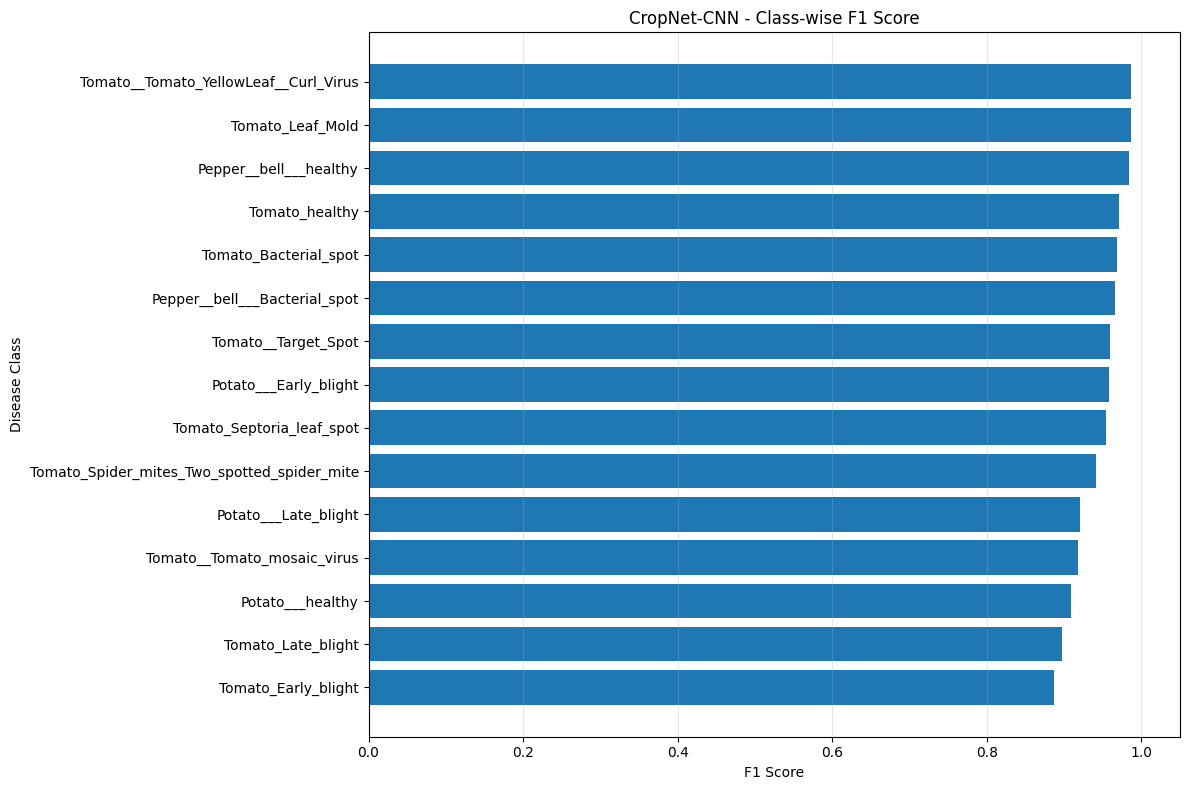

Class-wise F1 graph saved!


In [76]:

# PART 5 - CELL 11
# Class-wise F1 Score Graph

plot_df = per_class_df.sort_values(
    "F1_Score",
    ascending=True
)

plt.figure(figsize=(12, 8))

plt.barh(
    plot_df["Class"],
    plot_df["F1_Score"]
)

plt.xlabel("F1 Score")
plt.ylabel("Disease Class")

plt.title(
    "CropNet-CNN - Class-wise F1 Score"
)

plt.xlim(0, 1.05)
plt.grid(axis="x", alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULT_DIR,
        "classwise_f1_score.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Class-wise F1 graph saved!")


In [77]:

# PART 5 - CELL 12
# Actual vs Predicted Comparison

comparison_df = pd.DataFrame({

    "Image Path": X_test,

    "Actual Class": [
        selected_classes[i] for i in y_true
    ],

    "Predicted Class": [
        selected_classes[i] for i in y_pred
    ],

    "Confidence (%)": (
        np.max(y_prob, axis=1) * 100
    ).round(2),

    "Correct Prediction": (
        y_true == y_pred
    )

})

print("========== ACTUAL VS PREDICTED ==========")

display(comparison_df.head(20))

print("\nCorrect Predictions:",
      int((y_true == y_pred).sum()))

print("Incorrect Predictions:",
      int((y_true != y_pred).sum()))

comparison_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "actual_vs_predicted.csv"
    ),
    index=False
)

print("\nComparison report saved!")


========== ACTUAL VS PREDICTED ==========


,Image Path,Actual Class,Predicted Class,Confidence (%),Correct Prediction
0,/content/Crop_Disease_Project/preprocessed_ima...,Tomato_Late_blight,Potato___Late_blight,51.119999,False
1,/content/Crop_Disease_Project/preprocessed_ima...,Tomato__Tomato_YellowLeaf__Curl_Virus,Tomato__Tomato_YellowLeaf__Curl_Virus,97.559998,True
2,/content/Crop_Disease_Project/preprocessed_ima...,Potato___Late_blight,Potato___Late_blight,96.760002,True
3,/content/Crop_Disease_Project/preprocessed_ima...,Tomato__Tomato_YellowLeaf__Curl_Virus,Tomato__Tomato_YellowLeaf__Curl_Virus,86.180000,True
4,/content/Crop_Disease_Project/preprocessed_ima...,Tomato_healthy,Tomato_healthy,100.000000,True
5,/content/Crop_Disease_Project/preprocessed_ima...,Potato___Late_blight,Potato___Late_blight,99.930000,True
6,/content/Crop_Disease_Project/preprocessed_ima...,Tomato_Septoria_leaf_spot,Tomato_Septoria_leaf_spot,98.809998,True
7,/content/Crop_Disease_Project/preprocessed_ima...,Potato___Late_blight,Potato___Late_blight,99.610001,True
8,/content/Crop_Disease_Project/preprocessed_ima...,Tomato_Late_blight,Tomato_Late_blight,89.110001,True
9,/content/Crop_Disease_Project/preprocessed_ima...,Tomato_Early_blight,Tomato_Early_blight,99.949997,True



Correct Predictions: 2956
Incorrect Predictions: 140

Comparison report saved!


In [78]:

# PART 5 - CELL 14
# Top-3 Prediction Analysis

top3_indices = np.argsort(
    y_prob,
    axis=1
)[:, -3:][:, ::-1]

top3_results = []

for i in range(len(y_true)):

    result = {
        "Image Path": X_test[i],
        "Actual Class": selected_classes[y_true[i]]
    }

    for rank in range(3):

        class_index = top3_indices[i, rank]

        result[f"Top {rank+1} Class"] = (
            selected_classes[class_index]
        )

        result[f"Top {rank+1} Confidence (%)"] = round(
            float(y_prob[i, class_index] * 100),
            2
        )

    top3_results.append(result)

top3_df = pd.DataFrame(top3_results)

display(top3_df.head(10))

top3_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "top3_predictions.csv"
    ),
    index=False
)

print("Top-3 prediction analysis completed!")


,Image Path,Actual Class,Top 1 Class,Top 1 Confidence (%),Top 2 Class,Top 2 Confidence (%),Top 3 Class,Top 3 Confidence (%)
0,/content/Crop_Disease_Project/preprocessed_ima...,Tomato_Late_blight,Potato___Late_blight,51.12,Tomato_Late_blight,48.00,Tomato_Early_blight,0.59
1,/content/Crop_Disease_Project/preprocessed_ima...,Tomato__Tomato_YellowLeaf__Curl_Virus,Tomato__Tomato_YellowLeaf__Curl_Virus,97.56,Tomato_Early_blight,0.77,Pepper__bell___Bacterial_spot,0.71
2,/content/Crop_Disease_Project/preprocessed_ima...,Potato___Late_blight,Potato___Late_blight,96.76,Tomato_Bacterial_spot,0.56,Pepper__bell___healthy,0.52
3,/content/Crop_Disease_Project/preprocessed_ima...,Tomato__Tomato_YellowLeaf__Curl_Virus,Tomato__Tomato_YellowLeaf__Curl_Virus,86.18,Tomato_Late_blight,3.25,Tomato_Spider_mites_Two_spotted_spider_mite,3.21
4,/content/Crop_Disease_Project/preprocessed_ima...,Tomato_healthy,Tomato_healthy,100.00,Tomato_Late_blight,0.00,Tomato_Leaf_Mold,0.00
5,/content/Crop_Disease_Project/preprocessed_ima...,Potato___Late_blight,Potato___Late_blight,99.93,Tomato_Late_blight,0.06,Tomato_Septoria_leaf_spot,0.00
6,/content/Crop_Disease_Project/preprocessed_ima...,Tomato_Septoria_leaf_spot,Tomato_Septoria_leaf_spot,98.81,Tomato_Early_blight,0.47,Tomato_Leaf_Mold,0.44
7,/content/Crop_Disease_Project/preprocessed_ima...,Potato___Late_blight,Potato___Late_blight,99.61,Potato___Early_blight,0.21,Tomato_Late_blight,0.12
8,/content/Crop_Disease_Project/preprocessed_ima...,Tomato_Late_blight,Tomato_Late_blight,89.11,Tomato_Early_blight,10.71,Potato___Early_blight,0.10
9,/content/Crop_Disease_Project/preprocessed_ima...,Tomato_Early_blight,Tomato_Early_blight,99.95,Potato___Early_blight,0.05,Tomato_Bacterial_spot,0.01


Top-3 prediction analysis completed!


In [79]:

# PART 5 - CELL 15
# CPU Inference Latency Measurement

NUM_BENCHMARK_IMAGES = min(100, len(X_test))

benchmark_images = []

for path in X_test[:NUM_BENCHMARK_IMAGES]:

    image = Image.open(path).convert("RGB")

    image = image.resize(
        (224, 224),
        Image.Resampling.BILINEAR
    )

    image_array = np.asarray(
        image,
        dtype=np.float32
    ) / 255.0

    benchmark_images.append(image_array)

benchmark_images = np.stack(benchmark_images)

cpu_latencies = []

with tf.device("/CPU:0"):

    # Warm-up
    for i in range(min(10, len(benchmark_images))):

        output = evaluation_model(
            benchmark_images[i:i+1],
            training=False
        )

        _ = output.numpy()

    # Actual benchmark
    for image in benchmark_images:

        input_tensor = tf.convert_to_tensor(
            image[np.newaxis, ...]
        )

        start_time = time.perf_counter()

        output = evaluation_model(
            input_tensor,
            training=False
        )

        _ = output.numpy()

        end_time = time.perf_counter()

        cpu_latencies.append(
            end_time - start_time
        )

cpu_mean = np.mean(cpu_latencies)
cpu_median = np.median(cpu_latencies)
cpu_max = np.max(cpu_latencies)

print("========== CPU LATENCY ==========")

print("Images Tested:", len(cpu_latencies))
print("Mean:", round(cpu_mean, 5), "seconds/image")
print("Median:", round(cpu_median, 5), "seconds/image")
print("Maximum:", round(cpu_max, 5), "seconds/image")

print("SRS CPU Target: <= 1.5 seconds/image")

print(
    "CPU Target Achieved:",
    cpu_mean <= 1.5
)


========== CPU LATENCY ==========
Images Tested: 100
Mean: 0.18204 seconds/image
Median: 0.18981 seconds/image
Maximum: 0.37162 seconds/image
SRS CPU Target: <= 1.5 seconds/image
CPU Target Achieved: True


In [80]:

# PART 5 - CELL 16
# GPU Inference Latency Measurement

gpu_devices = tf.config.list_physical_devices("GPU")

gpu_latencies = []

if gpu_devices:

    with tf.device("/GPU:0"):

        # Warm-up
        for i in range(min(10, len(benchmark_images))):

            output = evaluation_model(
                benchmark_images[i:i+1],
                training=False
            )

            _ = output.numpy()

        # Actual benchmark
        for image in benchmark_images:

            input_tensor = tf.convert_to_tensor(
                image[np.newaxis, ...]
            )

            start_time = time.perf_counter()

            output = evaluation_model(
                input_tensor,
                training=False
            )

            _ = output.numpy()

            end_time = time.perf_counter()

            gpu_latencies.append(
                end_time - start_time
            )

    gpu_mean = float(np.mean(gpu_latencies))

    print("========== GPU LATENCY ==========")

    print("GPU:", gpu_devices[0])
    print("Images Tested:", len(gpu_latencies))

    print(
        "Mean:",
        round(gpu_mean, 5),
        "seconds/image"
    )

    print(
        "Median:",
        round(float(np.median(gpu_latencies)), 5),
        "seconds/image"
    )

    print("SRS GPU Target: <= 0.2 seconds/image")

    print(
        "GPU Target Achieved:",
        gpu_mean <= 0.2
    )

else:

    gpu_mean = None

    print("GPU unavailable.")
    print("GPU benchmark skipped.")


========== GPU LATENCY ==========
GPU: PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')
Images Tested: 100
Mean: 0.08832 seconds/image
Median: 0.0664 seconds/image
SRS GPU Target: <= 0.2 seconds/image
GPU Target Achieved: True


,Device,Mean Latency (seconds),SRS Limit (seconds)
0,CPU,0.18204,1.5
1,GPU,0.08832,0.2


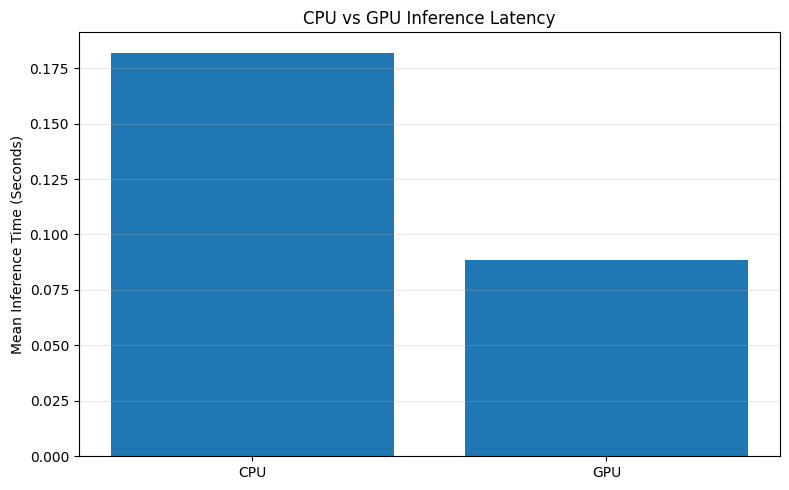

Latency comparison completed!


In [81]:

# PART 5 - CELL 17
# CPU vs GPU Latency Comparison

latency_data = {
    "Device": ["CPU"],
    "Mean Latency (seconds)": [cpu_mean],
    "SRS Limit (seconds)": [1.5]
}

if gpu_mean is not None:

    latency_data["Device"].append("GPU")

    latency_data["Mean Latency (seconds)"].append(
        gpu_mean
    )

    latency_data["SRS Limit (seconds)"].append(0.2)

latency_df = pd.DataFrame(latency_data)

display(latency_df.round(5))

plt.figure(figsize=(8, 5))

plt.bar(
    latency_df["Device"],
    latency_df["Mean Latency (seconds)"]
)

plt.ylabel("Mean Inference Time (Seconds)")
plt.title("CPU vs GPU Inference Latency")

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULT_DIR,
        "cpu_gpu_latency_comparison.png"
    ),
    dpi=300
)

plt.show()

latency_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "latency_comparison.csv"
    ),
    index=False
)

print("Latency comparison completed!")


In [82]:

# PART 5 - CELL 18
# Final Model Evaluation Summary

evaluation_summary = {

    "model": "CropNet-CNN",

    "total_test_images": int(len(y_true)),

    "number_of_classes": int(NUM_CLASSES),

    "test_accuracy": float(test_accuracy_manual),

    "test_accuracy_percentage": float(
        test_accuracy_manual * 100
    ),

    "test_loss": float(test_loss),

    "macro_precision": float(macro_precision),

    "macro_recall": float(macro_recall),

    "macro_f1_score": float(macro_f1),

    "weighted_precision": float(weighted_precision),

    "weighted_recall": float(weighted_recall),

    "weighted_f1_score": float(weighted_f1),

    "cpu_mean_latency_seconds": float(cpu_mean),

    "gpu_mean_latency_seconds": (
        float(gpu_mean)
        if gpu_mean is not None else None
    ),

    "srs_test_accuracy_target": 0.94,

    "srs_macro_f1_target": 0.93,

    "cpu_latency_target_seconds": 1.5,

    "gpu_latency_target_seconds": 0.2,

    "accuracy_target_achieved": bool(
        test_accuracy_manual >= 0.94
    ),

    "macro_f1_target_achieved": bool(
        macro_f1 >= 0.93
    ),

    "cpu_latency_target_achieved": bool(
        cpu_mean <= 1.5
    ),

    "gpu_latency_target_achieved": (
        bool(gpu_mean <= 0.2)
        if gpu_mean is not None else None
    )
}

summary_path = os.path.join(
    RESULT_DIR,
    "final_evaluation_summary.json"
)

with open(summary_path, "w") as f:

    json.dump(
        evaluation_summary,
        f,
        indent=4
    )

print("========== FINAL EVALUATION SUMMARY ==========")

print(json.dumps(evaluation_summary, indent=4))

print("\nFinal evaluation summary saved!")


========== FINAL EVALUATION SUMMARY ==========
{
    "model": "CropNet-CNN",
    "total_test_images": 3096,
    "number_of_classes": 15,
    "test_accuracy": 0.9547803617571059,
    "test_accuracy_percentage": 95.47803617571059,
    "test_loss": 0.1486797332763672,
    "macro_precision": 0.9452196705549253,
    "macro_recall": 0.9517943779136507,
    "macro_f1_score": 0.9471228645873193,
    "weighted_precision": 0.9564864770498428,
    "weighted_recall": 0.9547803617571059,
    "weighted_f1_score": 0.9544434231514616,
    "cpu_mean_latency_seconds": 0.1820405237799696,
    "gpu_mean_latency_seconds": 0.08831721105002543,
    "srs_test_accuracy_target": 0.94,
    "srs_macro_f1_target": 0.93,
    "cpu_latency_target_seconds": 1.5,
    "gpu_latency_target_seconds": 0.2,
    "accuracy_target_achieved": true,
    "macro_f1_target_achieved": true,
    "cpu_latency_target_achieved": true,
    "gpu_latency_target_achieved": true
}

Final evaluation summary saved!


In [83]:

# PART 5 - CELL 19
# Create Report-Ready Evaluation Table

report_metrics = pd.DataFrame({

    "Evaluation Metric": [
        "Test Accuracy",
        "Macro Precision",
        "Macro Recall",
        "Macro F1-Score",
        "Weighted Precision",
        "Weighted Recall",
        "Weighted F1-Score",
        "Test Loss",
        "Mean CPU Latency"
    ],

    "Actual Result": [
        f"{test_accuracy_manual * 100:.2f}%",
        f"{macro_precision:.4f}",
        f"{macro_recall:.4f}",
        f"{macro_f1:.4f}",
        f"{weighted_precision:.4f}",
        f"{weighted_recall:.4f}",
        f"{weighted_f1:.4f}",
        f"{test_loss:.4f}",
        f"{cpu_mean:.5f} sec"
    ],

    "SRS Target": [
        ">= 94%",
        "Reported in evaluation",
        "Reported in evaluation",
        ">= 0.93",
        "Reported in evaluation",
        "Reported in evaluation",
        "Reported in evaluation",
        "Not specified",
        "<= 1.5 sec"
    ]

})

display(report_metrics)

report_metrics.to_csv(
    os.path.join(
        RESULT_DIR,
        "report_ready_performance_metrics.csv"
    ),
    index=False
)

print("Report-ready performance table saved!")


,Evaluation Metric,Actual Result,SRS Target
0,Test Accuracy,95.48%,>= 94%
1,Macro Precision,0.9452,Reported in evaluation
2,Macro Recall,0.9518,Reported in evaluation
3,Macro F1-Score,0.9471,>= 0.93
4,Weighted Precision,0.9565,Reported in evaluation
5,Weighted Recall,0.9548,Reported in evaluation
6,Weighted F1-Score,0.9544,Reported in evaluation
7,Test Loss,0.1487,Not specified
8,Mean CPU Latency,0.18204 sec,<= 1.5 sec


Report-ready performance table saved!


In [84]:

# PART 5 - CELL 20
# Save All Evaluation Outputs

# Save confusion matrix
cm_df = pd.DataFrame(
    cm,
    index=selected_classes,
    columns=selected_classes
)

cm_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "confusion_matrix.csv"
    )
)

# Save predictions and probabilities
prediction_output = comparison_df.copy()

for i, class_name in enumerate(selected_classes):

    prediction_output[
        f"Probability_{class_name}"
    ] = y_prob[:, i]

prediction_output.to_csv(
    os.path.join(
        RESULT_DIR,
        "complete_test_predictions.csv"
    ),
    index=False
)

# Save class-wise statistics
per_class_df.to_csv(
    os.path.join(
        RESULT_DIR,
        "per_class_performance.csv"
    ),
    index=False
)

print("All evaluation files saved successfully!")

print("\nResults Directory:", RESULT_DIR)


All evaluation files saved successfully!

Results Directory: /content/Crop_Disease_Project/results


In [85]:

# PART 5 - CELL 21
# Verify Evaluation Files

expected_files = [

    "classification_report.csv",
    "per_class_performance.csv",
    "confusion_matrix.csv",
    "confusion_matrix_15_classes.png",
    "classwise_f1_score.png",
    "actual_vs_predicted.csv",
    "actual_vs_predicted_visualization.png",
    "top3_predictions.csv",
    "cpu_gpu_latency_comparison.png",
    "latency_comparison.csv",
    "final_evaluation_summary.json",
    "report_ready_performance_metrics.csv",
    "complete_test_predictions.csv"

]

print("========== EVALUATION FILE VERIFICATION ==========")

for filename in expected_files:

    file_path = os.path.join(
        RESULT_DIR,
        filename
    )

    status = "EXISTS" if os.path.exists(file_path) else "MISSING"

    print(filename, ":", status)

print("\nFile verification completed!")


========== EVALUATION FILE VERIFICATION ==========
classification_report.csv : EXISTS
per_class_performance.csv : EXISTS
confusion_matrix.csv : EXISTS
confusion_matrix_15_classes.png : EXISTS
classwise_f1_score.png : EXISTS
actual_vs_predicted.csv : EXISTS
actual_vs_predicted_visualization.png : MISSING
top3_predictions.csv : EXISTS
cpu_gpu_latency_comparison.png : EXISTS
latency_comparison.csv : EXISTS
final_evaluation_summary.json : EXISTS
report_ready_performance_metrics.csv : EXISTS
complete_test_predictions.csv : EXISTS

File verification completed!


In [86]:

# PART 6 - CELL 1
# Create Streamlit Deployment Directory

import os
import json
import shutil

PROJECT_DIR = "/content/Crop_Disease_Project"

MODEL_DIR = os.path.join(
    PROJECT_DIR,
    "models"
)

RESULT_DIR = os.path.join(
    PROJECT_DIR,
    "results"
)

DEPLOY_DIR = os.path.join(
    PROJECT_DIR,
    "deployment"
)

os.makedirs(DEPLOY_DIR, exist_ok=True)

print("Project Directory:", PROJECT_DIR)
print("Model Directory:", MODEL_DIR)
print("Deployment Directory:", DEPLOY_DIR)

print("\nProject folders created successfully!")


Project Directory: /content/Crop_Disease_Project
Model Directory: /content/Crop_Disease_Project/models
Deployment Directory: /content/Crop_Disease_Project/deployment

Project folders created successfully!


In [87]:

# PART 6 - CELL 2
# Verify Model and Class Mapping

BEST_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "CropNet_CNN_Best.keras"
)

FINAL_MODEL_PATH = os.path.join(
    MODEL_DIR,
    "CropNet_CNN_Final.keras"
)

CLASS_MAPPING_PATH = os.path.join(
    PROJECT_DIR,
    "class_mapping.json"
)

print("Best Model Exists:",
      os.path.exists(BEST_MODEL_PATH))

print("Final Model Exists:",
      os.path.exists(FINAL_MODEL_PATH))

print("Class Mapping Exists:",
      os.path.exists(CLASS_MAPPING_PATH))

assert os.path.exists(BEST_MODEL_PATH), (
    "Best model missing. Complete Part 4 first."
)

assert os.path.exists(CLASS_MAPPING_PATH), (
    "class_mapping.json missing. "
    "Use the original class mapping created in Part 2."
)

with open(CLASS_MAPPING_PATH, "r") as f:
    class_mapping = json.load(f)

print("\nClass Mapping Content:")
print(json.dumps(class_mapping, indent=4))


Best Model Exists: True
Final Model Exists: True
Class Mapping Exists: True

Class Mapping Content:
{
    "0": "Pepper__bell___Bacterial_spot",
    "1": "Pepper__bell___healthy",
    "2": "Potato___Early_blight",
    "3": "Potato___Late_blight",
    "4": "Potato___healthy",
    "5": "Tomato_Bacterial_spot",
    "6": "Tomato_Early_blight",
    "7": "Tomato_Late_blight",
    "8": "Tomato_Leaf_Mold",
    "9": "Tomato_Septoria_leaf_spot",
    "10": "Tomato_Spider_mites_Two_spotted_spider_mite",
    "11": "Tomato__Target_Spot",
    "12": "Tomato__Tomato_YellowLeaf__Curl_Virus",
    "13": "Tomato__Tomato_mosaic_virus",
    "14": "Tomato_healthy"
}


In [88]:

# PART 6 - CELL 3
# Copy Model and Class Mapping

DEPLOY_MODEL_PATH = os.path.join(
    DEPLOY_DIR,
    "CropNet_CNN_Best.keras"
)

DEPLOY_MAPPING_PATH = os.path.join(
    DEPLOY_DIR,
    "class_mapping.json"
)

shutil.copy2(
    BEST_MODEL_PATH,
    DEPLOY_MODEL_PATH
)

shutil.copy2(
    CLASS_MAPPING_PATH,
    DEPLOY_MAPPING_PATH
)

print("Model copied:", DEPLOY_MODEL_PATH)
print("Mapping copied:", DEPLOY_MAPPING_PATH)

print(
    "Model Size:",
    round(os.path.getsize(DEPLOY_MODEL_PATH) / (1024**2), 2),
    "MB"
)

print("\nDeployment model preparation completed!")


Model copied: /content/Crop_Disease_Project/deployment/CropNet_CNN_Best.keras
Mapping copied: /content/Crop_Disease_Project/deployment/class_mapping.json
Model Size: 28.65 MB

Deployment model preparation completed!


In [89]:

# PART 6 - CELL 4
# Install Streamlit and Required Libraries

%pip install -q streamlit pillow numpy pandas


In [90]:

# PART 6 - CELL 5
# Verify Streamlit Installation

import streamlit as st
import tensorflow as tf
import PIL
import numpy as np

print("Streamlit:", st.__version__)
print("TensorFlow:", tf.__version__)
print("Pillow:", PIL.__version__)
print("NumPy:", np.__version__)

print("\nAll required libraries are available!")


Streamlit: 1.67.0
TensorFlow: 2.21.0
Pillow: 11.3.0
NumPy: 2.4.6

All required libraries are available!


In [91]:

# PART 6 - CELL 6
# Create Complete Streamlit Application

%%writefile /content/Crop_Disease_Project/deployment/app.py

import os
import json
import time

import streamlit as st
import tensorflow as tf
import numpy as np

from PIL import Image, UnidentifiedImageError


# =====================================================
# 1. APPLICATION CONFIGURATION
# =====================================================

st.set_page_config(
    page_title="CropNet-CNN | Leaf Disease Detection",
    page_icon="🌿",
    layout="wide"
)

APP_DIR = os.path.dirname(os.path.abspath(__file__))

MODEL_PATH = os.path.join(
    APP_DIR,
    "CropNet_CNN_Best.keras"
)

MAPPING_PATH = os.path.join(
    APP_DIR,
    "class_mapping.json"
)

IMAGE_SIZE = (224, 224)

MAX_FILE_SIZE = 10 * 1024 * 1024

CONFIDENCE_THRESHOLD = 0.60

ALLOWED_EXTENSIONS = [
    "jpg",
    "jpeg",
    "png",
    "webp"
]


# =====================================================
# 2. PAGE DESIGN
# =====================================================

st.title("🌿 CropNet-CNN")

st.subheader(
    "Automated Crop Leaf Disease Detection System"
)

st.write(
    "Upload a crop leaf image to identify its "
    "predicted crop species and leaf disease."
)

st.info(
    "AI-powered leaf disease screening using "
    "a trained Convolutional Neural Network."
)

st.divider()


# =====================================================
# 3. LOAD CLASS MAPPING
# =====================================================

@st.cache_data
def load_class_names():

    with open(MAPPING_PATH, "r") as file:

        mapping = json.load(file)

    if isinstance(mapping, list):

        class_names = mapping

    elif isinstance(mapping, dict):

        # Supports index-to-class mappings
        if all(str(k).isdigit() for k in mapping):

            class_names = [
                mapping[k]
                for k in sorted(
                    mapping,
                    key=lambda x: int(x)
                )
            ]

        # Supports class-to-index mappings
        elif all(
            isinstance(v, int)
            for v in mapping.values()
        ):

            class_names = [
                name
                for name, index in sorted(
                    mapping.items(),
                    key=lambda item: item[1]
                )
            ]

        else:

            raise ValueError(
                "Unsupported class mapping format."
            )

    else:

        raise ValueError(
            "Invalid class mapping format."
        )

    if len(class_names) != 15:

        raise ValueError(
            f"Expected 15 classes, found {len(class_names)}."
        )

    return [str(name) for name in class_names]


# =====================================================
# 4. LOAD TRAINED CNN MODEL
# =====================================================

@st.cache_resource
def load_cropnet_model():

    if not os.path.exists(MODEL_PATH):

        raise FileNotFoundError(
            "Trained CropNet-CNN model not found."
        )

    model = tf.keras.models.load_model(
        MODEL_PATH,
        compile=False
    )

    if model.input_shape != (None, 224, 224, 3):

        raise ValueError(
            f"Unexpected input shape: {model.input_shape}"
        )

    if model.output_shape[-1] != 15:

        raise ValueError(
            "Model must generate 15 class probabilities."
        )

    return model


try:

    class_names = load_class_names()

    model = load_cropnet_model()

    st.success(
        "CropNet-CNN model loaded successfully!"
    )

except Exception as error:

    st.error(
        f"Application initialization failed: {error}"
    )

    st.stop()


# =====================================================
# 5. IMAGE PREPROCESSING FUNCTION
# =====================================================

def preprocess_leaf_image(uploaded_file):

    uploaded_file.seek(0)

    image = Image.open(
        uploaded_file
    )

    image.load()

    if image.width <= 0 or image.height <= 0:

        raise ValueError(
            "Image dimensions must be greater than zero."
        )

    # Convert uploaded image to RGB
    image = image.convert("RGB")

    # Bilinear resizing
    resized_image = image.resize(
        IMAGE_SIZE,
        Image.Resampling.BILINEAR
    )

    # Convert pixels to float32 and normalize
    image_array = np.asarray(
        resized_image,
        dtype=np.float32
    ) / 255.0

    # Add batch dimension
    image_tensor = np.expand_dims(
        image_array,
        axis=0
    )

    return image, resized_image, image_tensor


# =====================================================
# 6. FILE UPLOAD SECTION
# =====================================================

st.header("📤 Upload Crop Leaf Image")

uploaded_file = st.file_uploader(
    "Choose a leaf image",
    type=ALLOWED_EXTENSIONS,
    help="Supported: JPG, JPEG, PNG and WEBP. Maximum size: 10 MB."
)


# =====================================================
# 7. VALIDATE AND PROCESS UPLOADED IMAGE
# =====================================================

if uploaded_file is not None:

    file_size = uploaded_file.size

    if file_size <= 0:

        st.error("Uploaded file is empty.")

        st.stop()

    if file_size > MAX_FILE_SIZE:

        st.error(
            "File size exceeds the maximum limit of 10 MB."
        )

        st.stop()

    try:

        original_image, processed_image, image_tensor = (
            preprocess_leaf_image(uploaded_file)
        )

    except (
        UnidentifiedImageError,
        OSError,
        ValueError
    ) as error:

        st.error(
            f"Invalid or corrupted image: {error}"
        )

        st.stop()

    st.success("Image validation successful!")

    st.write(
        f"File size: {file_size / (1024 * 1024):.2f} MB"
    )

    st.write(
        f"Original dimensions: "
        f"{original_image.width} × {original_image.height}"
    )

    st.write(
        f"Processed tensor shape: {image_tensor.shape}"
    )

    st.write(
        f"Pixel range: "
        f"{image_tensor.min():.3f} to "
        f"{image_tensor.max():.3f}"
    )

    # =================================================
    # 8. DISPLAY UPLOADED IMAGE
    # =================================================

    st.divider()

    st.header("🖼️ Uploaded Leaf Image")

    col1, col2 = st.columns(2)

    with col1:

        st.image(
            original_image,
            caption="Original Uploaded Image",
            use_container_width=True
        )

    with col2:

        st.image(
            processed_image,
            caption="224 × 224 Processed Image",
            use_container_width=True
        )

    # =================================================
    # 9. MODEL INFERENCE
    # =================================================

    st.divider()

    st.header("🔍 Disease Detection Result")

    with st.spinner(
        "Analyzing leaf image using CropNet-CNN..."
    ):

        start_time = time.perf_counter()

        probabilities = model(
            image_tensor,
            training=False
        ).numpy()[0]

        inference_time = (
            time.perf_counter() - start_time
        )

    if not np.all(np.isfinite(probabilities)):

        st.error(
            "Model generated invalid probability values."
        )

        st.stop()

    if not np.isclose(
        np.sum(probabilities),
        1.0,
        atol=1e-4
    ):

        st.error(
            "Invalid Softmax probability distribution."
        )

        st.stop()

    # =================================================
    # 10. TOP-1 PREDICTION
    # =================================================

    predicted_index = int(
        np.argmax(probabilities)
    )

    predicted_class = class_names[
        predicted_index
    ]

    confidence = float(
        probabilities[predicted_index]
    )

    confidence_percentage = confidence * 100

    # =================================================
    # 11. PARSE CROP AND DISEASE NAME
    # =================================================

    if "___" in predicted_class:

        crop_name, disease_name = (
            predicted_class.split("___", 1)
        )

    else:

        crop_name = "Not specified"

        disease_name = predicted_class

    crop_name = crop_name.replace("_", " ")

    disease_name = disease_name.replace("_", " ")

    is_healthy = (
        disease_name.strip().lower() == "healthy"
    )

    # =================================================
    # 12. DISPLAY DIAGNOSTIC RESULT
    # =================================================

    result_col1, result_col2 = st.columns(2)

    with result_col1:

        st.metric(
            "Predicted Crop",
            crop_name
        )

    with result_col2:

        st.metric(
            "Confidence",
            f"{confidence_percentage:.2f}%"
        )

    st.subheader(
        "Predicted Condition"
    )

    st.write(
        f"**{disease_name}**"
    )

    # =================================================
    # 13. LOW CONFIDENCE WARNING
    # =================================================

    if confidence < CONFIDENCE_THRESHOLD:

        st.warning(
            "⚠️ Uncertain / Out-of-Distribution. "
            "The model confidence is below 60%. "
            "Please capture a clearer leaf image "
            "and try again."
        )

    elif is_healthy:

        st.success(
            "The model predicts a healthy leaf."
        )

    else:

        st.success(
            "The model predicts a possible leaf disease."
        )

    # =================================================
    # 14. TOP-3 PREDICTIONS
    # =================================================

    st.divider()

    st.header("🏆 Top-3 Predictions")

    top_indices = np.argsort(
        probabilities
    )[::-1][:3]

    for rank, index in enumerate(
        top_indices,
        start=1
    ):

        class_name = class_names[index]

        probability = float(
            probabilities[index]
        )

        percentage = probability * 100

        st.write(
            f"**{rank}. {class_name.replace('_', ' ')}**"
        )

        st.progress(
            probability,
            text=f"{percentage:.2f}%"
        )

    # =================================================
    # 15. INFERENCE INFORMATION
    # =================================================

    st.divider()

    st.subheader("⚙️ Inference Information")

    st.write(
        f"Model: CropNet-CNN"
    )

    st.write(
        f"Input Tensor: {image_tensor.shape}"
    )

    st.write(
        f"Number of Classes: {len(class_names)}"
    )

    st.write(
        f"Inference Time: {inference_time:.5f} seconds"
    )

    st.caption(
        "This application provides AI-based preliminary "
        "screening. Predictions should not replace "
        "professional agricultural diagnosis."
    )

else:

    st.info(
        "Please upload a crop leaf image to start detection."
    )


# =====================================================
# 16. FOOTER
# =====================================================

st.divider()

st.caption(
    "CropNet-CNN | Automated Crop Leaf Disease Detection System"
)

st.caption(
    "Academic Project – Neural Network & Deep Learning"
)


Writing /content/Crop_Disease_Project/deployment/app.py


In [92]:

# PART 6 - CELL 7
# Create Requirements File

requirements = """
streamlit
tensorflow==2.21.0
numpy
pillow
pandas
"""

requirements_path = os.path.join(
    DEPLOY_DIR,
    "requirements.txt"
)

with open(requirements_path, "w") as f:
    f.write(requirements.strip() + "\n")

print("requirements.txt created!")

print(requirements)


requirements.txt created!

streamlit
tensorflow==2.21.0
numpy
pillow
pandas



In [93]:

# PART 6 - CELL 8
# Verify Application Syntax

APP_PATH = os.path.join(
    DEPLOY_DIR,
    "app.py"
)

assert os.path.exists(APP_PATH)

with open(APP_PATH, "r") as f:
    app_source = f.read()

compile(
    app_source,
    APP_PATH,
    "exec"
)

print("SUCCESS: No Python syntax errors!")
print("Application file:", APP_PATH)
print("Application size:",
      round(os.path.getsize(APP_PATH) / 1024, 2),
      "KB")


SUCCESS: No Python syntax errors!
Application file: /content/Crop_Disease_Project/deployment/app.py
Application size: 11.0 KB


In [94]:

# PART 6 - CELL 9
# Verify Deployment Package

deployment_files = [
    "app.py",
    "requirements.txt",
    "CropNet_CNN_Best.keras",
    "class_mapping.json"
]

print("========== DEPLOYMENT PACKAGE ==========")

for filename in deployment_files:

    path = os.path.join(
        DEPLOY_DIR,
        filename
    )

    exists = os.path.exists(path)

    print(
        filename,
        ":",
        "READY" if exists else "MISSING"
    )

    assert exists, f"Missing file: {filename}"

print("\nAll deployment files are ready!")


========== DEPLOYMENT PACKAGE ==========
app.py : READY
requirements.txt : READY
CropNet_CNN_Best.keras : READY
class_mapping.json : READY

All deployment files are ready!


In [95]:

# PART 6 - CELL 10
# Create Deployment ZIP

ZIP_PATH = os.path.join(
    PROJECT_DIR,
    "CropNet_Streamlit_Deployment"
)

shutil.make_archive(
    ZIP_PATH,
    "zip",
    DEPLOY_DIR
)

FINAL_ZIP = ZIP_PATH + ".zip"

print("Deployment ZIP created!")
print("Path:", FINAL_ZIP)

print(
    "ZIP Size:",
    round(os.path.getsize(FINAL_ZIP) / (1024 * 1024), 2),
    "MB"
)


Deployment ZIP created!
Path: /content/Crop_Disease_Project/CropNet_Streamlit_Deployment.zip
ZIP Size: 26.41 MB


In [96]:

# PART 6 - CELL 11
# Download Deployment ZIP

from google.colab import files

files.download(FINAL_ZIP)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>